# 25 · Autoencodeurs et VAE — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch25_autoencodeurs/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 25.Q1 à 25.Q12, 25.R1 à 25.R3, 25.1 à 25.4, 25.6, 25.7 | vérifier tes réponses courtes | 🧠 🔁 ✏️ ∂ | ★ à ★★★ | |
| A | 25.14 | Prédire : un autoencodeur entraîné sur une seule image | 🔮 | ★ | 15 |
|  | 25.15 | Premier autoencodeur dense 784-20-784 en PyTorch | 📦 | ★★ | 25 |
|  | 25.16 | Autoencodeur profond 512-256-128-20 | 📦 | ★★ | 25 |
|  | 25.17 | Prédire : ce qu'un autoencodeur de chiffres fait d'un vêtement | 🔮 | ★★ | 15 |
|  | 25.18 | Reproduire la carte latente 2D et sa grille décodée (fig. 25.29-25.30) | 🎨 | ★★ | 30 |
|  | 25.19 | Secouer les variables latentes : bruit global, une seule composante, latents aléatoires | 🔬 | ★★ | 25 |
|  | 25.20 | Interpoler entre deux codes : linéaire et sphérique | 🔨 | ★★ | 20 |
|  | 25.21 | Mélanger dans l'espace des pixels ou dans l'espace latent | 🔬 | ★★ | 25 |
|  | 25.22 | Taille du goulot et profondeur : la courbe d'erreur de reconstruction | 🔬 | ★★★ | 40 |
|  | 25.23 | L'autoencodeur linéaire face à l'ACP de scikit-learn | 🔬 | ★★★ | 40 |
| B | 25.24 | Autoencodeur convolutif à 147 latents | 📦 | ★★ | 30 |
|  | 25.25 | Le débruiteur qui apprenait le bruit | 🐛 | ★★ | 25 |
|  | 25.26 | Autoencodeur débruiteur (bruit gaussien, écrêtage) | 📦 | ★★ | 30 |
|  | 25.27 | Sur-échantillonnage explicite ou convolutions à pas : temps et qualité | 🔬 | ★★★ | 35 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Construire et entraîner en PyTorch des autoencodeurs denses, convolutifs et débruiteurs, et explorer leur espace latent (carte 2D, bruit, interpolation).
- Relier l'autoencodeur linéaire à l'ACP ; mesurer un débruitage (PSNR).
- Écrire en NumPy le cœur du VAE (`mylearn.vae`), entraîner un VAE, régler β, générer, détecter des anomalies.

**Rappel express.** $\mathbf{z} = f_\theta(\mathbf{x})$, $\hat{\mathbf{x}} = g_\phi(\mathbf{z})$, la cible est l'entrée. Convolution transposée : $H_{out} = (H_{in} - 1)s - 2p + k + p_{out}$. PSNR $= 10 \log_{10}(1/\text{MSE})$ pour des pixels dans $[0, 1]$. VAE : $\mathbf{z} = \boldsymbol{\mu} + e^{\frac{1}{2}\log\boldsymbol{\sigma}^2} \odot \boldsymbol{\varepsilon}$, loss = reconstruction + $\beta$ KL, $\mathrm{KL} = \tfrac{1}{2}\sum_j (\mu_j^2 + \sigma_j^2 - 1 - \ln\sigma_j^2)$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 25.1 à 25.4 et 25.6, ∂ 25.7)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"F"`) ; plusieurs lettres : entre guillemets (`"AF"`) ; une forme ou un vecteur : entre guillemets (`"(3, 5, 1)"`, `"(1, -2)"`) ; un mot : entre guillemets (`"ABCD"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ 25.5 et 25.8 et la démarche de ∂ 25.7, les estimations 🧮 25.9 et 25.10, la réflexion (🗣️ 25.11, ⚖️ 25.12, 📄 25.13) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math


def dense(n_in, n_out):
    """Parameters of nn.Linear(n_in, n_out): weights and biases."""
    return (n_in + 1) * n_out


def conv_params(c_in, c_out, k):
    """Parameters of nn.Conv2d(c_in, c_out, k) (or ConvTranspose2d): weights and one bias per output channel."""
    return c_out * (c_in * k * k + 1)


def conv_out(h, k, s=1, p=0):
    """Height after nn.Conv2d(kernel_size=k, stride=s, padding=p)."""
    return (h + 2 * p - k) // s + 1


def tconv_out(h, k, s=1, p=0, op=0):
    """Height after nn.ConvTranspose2d(kernel_size=k, stride=s, padding=p, output_padding=op)."""
    return (h - 1) * s - 2 * p + k + op


def mlp_params(sizes):
    return sum(dense(a, b) for a, b in zip(sizes, sizes[1:]))


def gaussian_kl(mu, var):
    """KL(N(mu, var) || N(0, 1)) in nats."""
    return 0.5 * (mu ** 2 + var - 1 - math.log(var))


def kl_bits(p, q):
    return sum(pi * math.log2(pi / qi) for pi, qi in zip(p, q))


def letter_mix(word_a, word_b):
    """The book's letter blend: the middle letter (the earlier one when there are two)."""
    out = ""
    for a, b in zip(word_a, word_b):
        lo, hi = sorted((ord(a), ord(b)))
        out += chr((lo + hi) // 2)
    return out


ENC_DEEP = [784, 512, 256, 128, 20]
P_ENC_DEEP = mlp_params(ENC_DEEP)
P_DEC_DEEP = mlp_params(ENC_DEEP[::-1])
P_ENC_CONV = conv_params(1, 16, 3) + conv_params(16, 8, 3) + conv_params(8, 3, 3)
P_DEC_CONV = conv_params(3, 16, 3) + conv_params(16, 1, 3)
A_25_2 = dict(cx=2.0, cy=2.0, r=1.0, g=1.0)
B_25_2 = dict(cx=10.0, cy=6.0, r=4.0, g=0.4)
MIX_25_2 = {key: 0.75 * A_25_2[key] + 0.25 * B_25_2[key] for key in A_25_2}

**25.Q1 — Avec ou sans perte : le test de l'inversibilité**

In [3]:
wb.record("25.Q1a", "AC", mistakes={"arrondir au degré : peut-on retrouver les décimales ?": "ABC",
          "JPEG jette de l'information, même en qualité 90": "ACE",
          "une photo en niveaux de gris : peut-on retrouver ses couleurs ?": "ACF",
          "une lettre sur deux : peut-on retrouver les lettres retirées ?": "ACD",
          "écrire en binaire change la forme d'un nombre : peut-on revenir au décimal ?": "C",
          "un fichier ZIP : retrouve-t-on le fichier exact en le décompressant ?": "A"})
wb.record("25.Q1b", True, mistakes={"applique le test de l'inversibilité : existe-t-il une autre façon d'être sans perte ?": False})
wb.record("25.Q1c", "B", mistakes={"l'erreur de reconstruction est petite mais pas nulle : retrouve-t-on l'image exacte ?": "A"})
wb.record("25.Q1d", 2_400_000 / 300_000, decimals=3, mistakes={"on divise la taille d'origine par la taille compressée, pas l'inverse": 0.125,
          "c'est la part des octets supprimés, pas le facteur de compression": 0.875})
wb.record("25.Q1e", False, mistakes={"compte les fichiers courts et les fichiers longs : y a-t-il assez de fichiers courts pour tous ?": True})

WB_ANSWER {"hash": "a863b7735631829bd1122a2bfb63862fe96e54f7971ae0f15447f74fbae6b68c", "id": "25.Q1a", "kind": "str", "mistakes": {"4b6edfa3f2ccfe3a18f2c8748cabcd90d093b3ffe15dc2f47709e3efaa898b95": "arrondir au degré : peut-on retrouver les décimales ?", "a5fcabb0ccf5b4bb02d17a17d8db26bdeb679267a4f264c128a644d740827efb": "JPEG jette de l'information, même en qualité 90", "bd35941dd9eb331c3f536a3148aff05211ce6a5e74c04ced4c8ea161f5907eae": "écrire en binaire change la forme d'un nombre : peut-on revenir au décimal ?", "c905d8b4481b57d57dfd4155c7750173dad900861ee85d19036377f4b65ce426": "un fichier ZIP : retrouve-t-on le fichier exact en le décompressant ?", "cfa914c17ea75b2c66202484332256377cc74b07469de72df87114dc03334c30": "une lettre sur deux : peut-on retrouver les lettres retirées ?", "dac0addf8caf292b64fba12274af86e63dc5576394bda7c2766f66be5043e462": "une photo en niveaux de gris : peut-on retrouver ses couleurs ?"}}
📝 Ex 25.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "99c77

**25.Q2 — Pourquoi JPEG et MP3 battent un autoencodeur généraliste**

In [4]:
wb.record("25.Q2a", "C", mistakes={"JPEG n'apprend rien : ses règles ont été écrites par des ingénieurs": "A",
          "JPEG jette de l'information : relis le §25.2.2": "B",
          "JPEG ne garde aucun catalogue d'images": "D"})
wb.record("25.Q2b", "C", mistakes={"le code a été appris sur un seul type d'images": "A",
          "simple pour toi, pas pour un code appris sur d'autres images": "B"})
wb.record("25.Q2c", False, mistakes={"relis la première page du chapitre : qui aurait quelque chose à craindre ?": True})
wb.record("25.Q2d", "AC", mistakes={"il manque un des deux usages : relis le §25.1": "A",
          "un seul usage : le livre en donne deux, relis le §25.1": "C",
          "chiffrer n'est pas comprimer : un autoencodeur ne cache rien": "ABC",
          "dater une image n'est pas un usage d'autoencodeur": "ACD"})
wb.record("25.Q2e", 128_000 * 180 / 8 / 1e6, decimals=2, mistakes={"8 bits par octet : as-tu divisé par 8 ?": 23.04,
          "3 minutes, c'est 180 secondes": 0.048,
          "un million d'octets, c'est 10⁶ octets, pas 2²⁰": 2.75})

WB_ANSWER {"hash": "5cfb442fec4855329ed06bdc16040039eb1227568849e7f6f1489efad6d81ac0", "id": "25.Q2a", "kind": "str", "mistakes": {"5026043125b0b9d37aa340149d5f1d3fcf61a0ded7fe8132df9e6c954da566c5": "JPEG ne garde aucun catalogue d'images", "81512e0d8153a19ab6a74de5eeec2a448c72e102fd5cebeb1dfd08db0629dbed": "JPEG n'apprend rien : ses règles ont été écrites par des ingénieurs", "e6d9b99e4fa60a941a147b6ccf79258410dce27b5b564fae5b4f35d54e11da90": "JPEG jette de l'information : relis le §25.2.2"}}
📝 Ex 25.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "09606bd5f7b4e6217e24fc3ca4b046fe0423cf715526ba3491925fa4bfc0a4a1", "id": "25.Q2b", "kind": "str", "mistakes": {"03b119b1461975186ed5f1f4cc4e5b0f835d8710332d1f949afca38edb135082": "le code a été appris sur un seul type d'images", "fbfbc4a232f8da4d122e3d70af9000b37314d07a633774d92a2d80b911e9a12f": "simple pour toi, pas pour un code appris sur d'autres images"}}
📝 Ex 25.Q2b : réponse enregistrée (str).
WB_ANSWER {"hash": "e9c4528d2e2beeada

**25.Q3 — Mélange de contenu ou mélange de paramètres ?**

In [5]:
wb.record("25.Q3a", "A", mistakes={"on mélange les pixels, pas ce qui décrit les objets": "B"})
wb.record("25.Q3b", letter_mix("LUNE", "SOIR"), mistakes={"quand il y a deux lettres au milieu, la règle prend la plus proche du début de l'alphabet": "PRLL",
          "la lettre du milieu, pas la plus petite des deux lettres": "LOIE"})
wb.record("25.Q3c", False, mistakes={"relis ce que donne le mélange des deux noms de fruits du livre": True})
wb.record("25.Q3d", "C", mistakes={"un code court peut être mal rangé : que faut-il entre des objets voisins ?": "A",
          "binaire ou non, ce qui compte est la place des codes les uns par rapport aux autres": "B",
          "« sans perte » ne dit rien de la place des codes entre eux": "D"})

WB_ANSWER {"hash": "b29201de1848cec878554cd9e9503d2450f7cfdeb54daac9345353cadaec854e", "id": "25.Q3a", "kind": "str", "mistakes": {"d51ee2f827576c7c89a28ed979a7d182724463f2c524a3ee8b527114c05c668b": "on mélange les pixels, pas ce qui décrit les objets"}}
📝 Ex 25.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "18c030fbb9c97149d1a3d9a493c6f8b9f09c0b65a3cdaa5a7cc59de9e7a41f2f", "id": "25.Q3b", "kind": "str", "mistakes": {"6081a5ec45b0ad2ca259e0a562d380b130c50e53948bbd775b462e48405e065c": "la lettre du milieu, pas la plus petite des deux lettres", "e252dad3d22351239648fd351186453c5d78e06d2a177ee21a4aaeecc0b52154": "quand il y a deux lettres au milieu, la règle prend la plus proche du début de l'alphabet"}}
📝 Ex 25.Q3b : réponse enregistrée (str).
WB_ANSWER {"hash": "46129e4e3a4a9ded624e7bb6df208f3cfe591d3c62f885cd9076b8be49cd36db", "id": "25.Q3c", "kind": "bool", "mistakes": {"6fca7e2541852f86c35a598cc279c138adc05c9e7c106763eea0ba6bbea90ecc": "relis ce que donne le mélange des deux no

**25.Q4 — Goulot, code, variables latentes : vrai ou faux**

In [6]:
wb.record("25.Q4a", False, mistakes={"la cible d'un autoencodeur, d'où vient-elle ?": True})
wb.record("25.Q4b", True, mistakes={"que cherche à reproduire un autoencodeur ?": False})
wb.record("25.Q4c", True, mistakes={"où se trouve le goulot, et que contient-il ?": False})
wb.record("25.Q4d", "C", mistakes={"il n'y a aucun label à fournir": "A",
          "c'est le terme du livre, corrigé dans la fiche": "B",
          "il n'y a ni agent ni récompense": "D"})
wb.record("25.Q4e", True, mistakes={"si le code est aussi grand que l'entrée, que peut faire le réseau le plus simple ?": False})

WB_ANSWER {"hash": "df52a432711f319c7f72e3e6fad0a66fa97fc2ddb59233784df8419e7969e893", "id": "25.Q4a", "kind": "bool", "mistakes": {"3e9c9fb6baead5a1d79080fc2b35efd361b21fb78aeaa42832086a453df4a35d": "la cible d'un autoencodeur, d'où vient-elle ?"}}
📝 Ex 25.Q4a : réponse enregistrée (bool).
WB_ANSWER {"hash": "de474429aa220d76d6c32326ab1eaea7085ec8276af638167ba64b005f47c02c", "id": "25.Q4b", "kind": "bool", "mistakes": {"db3203584abc3d93d10914278254addd161b41cd4c0168cf1d6ac9339c5d1b85": "que cherche à reproduire un autoencodeur ?"}}
📝 Ex 25.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash": "cb345cd4706162d180e619a945a58146a9b2bdefa3b329d2c925564820096216", "id": "25.Q4c", "kind": "bool", "mistakes": {"3b10992ca0befe434d0df4fb23c47ffc3c54df344cf02b3b1f9fc3dc95728280": "où se trouve le goulot, et que contient-il ?"}}
📝 Ex 25.Q4c : réponse enregistrée (bool).
WB_ANSWER {"hash": "946c5b8be96dc1e74fbe8a9dc099d847d3453c0f9d62ea46ce53004f3c8ec367", "id": "25.Q4d", "kind": "str", "mistakes"

**25.Q5 — Le réseau qui ne savait redessiner qu'une image**

In [7]:
wb.record("25.Q5a", 2 * 4096 * 10, mistakes={"deux couches : l'encodeur et le décodeur ont chacune leurs poids": 4096 * 10,
          "une image de 64 × 64 a 64 × 64 pixels, pas 64 + 64": 2 * 128 * 10,
          "relis la question : sans les biais": 2 * 4096 * 10 + 4096 + 10})
wb.record("25.Q5b", 64 * 64, mistakes={"un biais par neurone de la couche de sortie : combien en a-t-elle ?": 10})
wb.record("25.Q5c", "C", mistakes={"les biais de la sortie ne dépendent pas de l'entrée": "A",
          "rien n'est tiré au hasard dans un réseau entraîné": "B",
          "le réseau accepte toute image de la bonne taille": "D"})
wb.record("25.Q5d", False, mistakes={"relis l'histoire du tigre : que montre l'image noire ?": True})
wb.record("25.Q5e", "C", mistakes={"sur ses images d'entraînement, un réseau qui mémorise semble excellent": "A",
          "le nombre d'epochs ne dit pas ce que le réseau a appris": "B",
          "la taille du goulot ne dit pas si le réseau triche": "D"})

WB_ANSWER {"hash": "75b19dfb3bb27e592eb9d7bc94caaa563004ad0c2faa5c330af03fad9302cfce", "id": "25.Q5a", "kind": "int", "magnitude": 4, "mistakes": {"5ab54d40751fa679bb7865e39a511f4b8dcdcb8c46e33076674e4fce3e0035ff": "deux couches : l'encodeur et le décodeur ont chacune leurs poids", "6c3074f5956cc579a0b31d3612c8bba79758184ae2b98e7c69223160c09c4a68": "relis la question : sans les biais", "937319c2e46792ec1030ed0f317099d923c1cfd29338e9c59c143a72e2f73a2f": "une image de 64 × 64 a 64 × 64 pixels, pas 64 + 64"}, "sign": 1}
📝 Ex 25.Q5a : réponse enregistrée (int).
WB_ANSWER {"hash": "19469699401dfbaff5d534dfeaebce82884150b4faa1a071df60c723cac4861e", "id": "25.Q5b", "kind": "int", "magnitude": 3, "mistakes": {"28675a29bf15811c2878abd7460f972f84b69885d02c2ad9fdbe525a863e52f5": "un biais par neurone de la couche de sortie : combien en a-t-elle ?"}, "sign": 1}
📝 Ex 25.Q5b : réponse enregistrée (int).
WB_ANSWER {"hash": "800792e6706b84bf8bb472476d4695261cfe741e0741c8e28253002ffc3a0920", "id": "25.

**25.Q6 — Profondeur ou nombre de latents : qui améliore quoi ?**

In [8]:
wb.record("25.Q6a", "C", mistakes={"moins de latents, c'est moins d'information dans le code": "A",
          "relis les figures 25.18 à 25.20": "B"})
wb.record("25.Q6b", "B", mistakes={"plus de couches, c'est plus de capacité pour calculer et décoder le code": "A",
          "relis la figure 25.22": "C"})
wb.record("25.Q6c", "AC", mistakes={"il manque une des deux conditions du livre": "A",
          "une condition manque": "C",
          "un autoencodeur n'a pas de labels": "ABC",
          "avec un learning rate nul, rien n'est appris": "ACD"})
wb.record("25.Q6d", False, mistakes={"le livre parle d'une habitude, pas d'une obligation": True})
wb.record("25.Q6e", "B", mistakes={"2 latents donnent des reconstructions très floues": "A",
          "la loss reste celle de la reconstruction": "C",
          "le décodeur sert toujours": "D"})

WB_ANSWER {"hash": "8540cf30729880fba28cf09a9fda90e68698d682972cc96f4db7a9294ccf97b1", "id": "25.Q6a", "kind": "str", "mistakes": {"0f5f92f29f11a71116605e8ace6b6fb8d3284aad88c1dc00aa4f6bd840ecb5f3": "relis les figures 25.18 à 25.20", "d50f049d168686f95b32bfbeaca3da0282f314a2b0a41fadcdd4687fca3a704c": "moins de latents, c'est moins d'information dans le code"}}
📝 Ex 25.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "bd0ef4bf8e7d4cda828d935c09cb2fedd837a87b2e41a05e3c28be83f7bdecc4", "id": "25.Q6b", "kind": "str", "mistakes": {"0b7644ea9f41d664b32ceda62e9eefa2fc9bce123fcd48c12aac24f6b7b5052f": "plus de couches, c'est plus de capacité pour calculer et décoder le code", "435e26cbc0f727f36499eb59da7314e6345e5f2e5b3220131b25bf35a9c6e6a5": "relis la figure 25.22"}}
📝 Ex 25.Q6b : réponse enregistrée (str).
WB_ANSWER {"hash": "bbee0cc53d7aec8accf215bebe1fbb11109773646834bf653587e6263070ce56", "id": "25.Q6c", "kind": "str", "mistakes": {"245843ed74cffda130f6a120798ee9ffc4959ff5f8df21b2435553

**25.Q7 — Du bruit dans l'espace latent d'un autoencodeur classique**

In [9]:
wb.record("25.Q7a", "B", mistakes={"compare la taille du bruit à celle des latents": "A"})
wb.record("25.Q7b", "A", mistakes={"compare la taille de ce bruit à celle des latents": "B"})
wb.record("25.Q7c", "A", mistakes={"chaque chiffre dépend plus ou moins de chaque latent": "B"})
wb.record("25.Q7d", False, mistakes={"relis ce que donnent des latents tirés au hasard": True})
wb.record("25.Q7e", "A", mistakes={"relis la figure 25.28": "B"})

WB_ANSWER {"hash": "c1affbfa48e90d3f561d243542eae5b7f8e96e2ad1e384b72c511d883a3a3b32", "id": "25.Q7a", "kind": "str", "mistakes": {"bfaee8f0aad6d79f79d51ee71465dcc9fa53b131a07745d3b5a1d3ccc3b3d360": "compare la taille du bruit à celle des latents"}}
📝 Ex 25.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "8bc0795dff132202501dcb05ed134f3fc4de1995ae02881cce1258fd2c87573d", "id": "25.Q7b", "kind": "str", "mistakes": {"6fe16ef5148ac7d8717fee4b9b83fca8a0c7fd10720615293b4e59bc3d7729ec": "compare la taille de ce bruit à celle des latents"}}
📝 Ex 25.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "e17e08f0c1f2110e33fa7ff75a4806d154f1bb8ce75f6022f470e30572603d07", "id": "25.Q7c", "kind": "str", "mistakes": {"753ac9485dc7e5e949e49f0f7fd21a5f118554c41e3c15d2322194ae66b114bf": "chaque chiffre dépend plus ou moins de chaque latent"}}
📝 Ex 25.Q7c : réponse enregistrée (str).
WB_ANSWER {"hash": "21818857e30de78d9eeb6cf0b44a466e11bfde221b88e5728f08f0cb01abdd43", "id": "25.Q7d", "kind": "bool",

**25.Q8 — Lire une carte latente à deux dimensions**

In [10]:
wb.record("25.Q8a", "A", mistakes={"la carte ne dit rien de la fréquence des chiffres": "B",
          "les points sont placés par l'encodeur, pas par le dessin": "C",
          "des codes voisins pour des chiffres différents, est-ce bon signe ?": "D"})
wb.record("25.Q8b", "B", mistakes={"aucun exemple n'a de code dans cette zone": "A",
          "le décodeur rend toujours une image, pas forcément noire": "C"})
wb.record("25.Q8c", "B", mistakes={"on mélange les codes, pas les pixels": "A"})
wb.record("25.Q8d", False, mistakes={"relis le §25.5.3 : que donnent certains mélanges ?": True})
wb.record("25.Q8e", "(5, 3)", mistakes={"le milieu est la moyenne des deux points : as-tu divisé par 2 ?": "(10, 6)",
          "c'est la différence des deux codes, pas leur milieu": "(6, -6)",
          "moyenne coordonnée par coordonnée : la première avec la première": "(4, 4)"})

WB_ANSWER {"hash": "87c99afe2e2f3f9ee819d87a6689c6f49773164a617e6fc279a17ea09fe8ce1a", "id": "25.Q8a", "kind": "str", "mistakes": {"5baaad89c15947ee1abce8fa3f3467faa07ab4d4bcce0b741a5a8a13ec596a6f": "la carte ne dit rien de la fréquence des chiffres", "63ddef8ac48de52a200dbaa6ebbd979fe097cac8b3c1be9544ced2d82a5dcd27": "les points sont placés par l'encodeur, pas par le dessin", "e9ebc45c6176537acba561b072cf868defbe4ff01427b8f65c7d613fccfb980e": "des codes voisins pour des chiffres différents, est-ce bon signe ?"}}
📝 Ex 25.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "33c3f7a32bb6c25499053fd170f76aa23b26bb2a54a4c00b4161c8f528c31c7c", "id": "25.Q8b", "kind": "str", "mistakes": {"19f6ee96bd36127dc6e05546792c732a46a616727526adbd9b5feacf64245d62": "le décodeur rend toujours une image, pas forcément noire", "558055d76b6fc3585695c92704cf0fc74a3389fe854cf55319125dfa754dbe9d": "aucun exemple n'a de code dans cette zone"}}
📝 Ex 25.Q8b : réponse enregistrée (str).
WB_ANSWER {"hash": "d9b564

**25.Q9 — Autoencodeur linéaire et ACP**

In [11]:
wb.record("25.Q9a", "B", mistakes={"rien ne force les latents à être orthogonaux ni rangés par variance": "A",
          "pas n'importe lequel : celui qui minimise l'erreur de reconstruction": "C",
          "garde-t-on les directions de plus grande ou de plus petite variance ?": "D"})
wb.record("25.Q9b", False, mistakes={"relis l'encadré « Le livre, corrigé » du §25.6": True})
wb.record("25.Q9c", True, mistakes={"l'ACP commence par centrer les données : qui le fait dans l'autoencodeur ?": False})
wb.record("25.Q9d", "A", mistakes={"aucun modèle ne garantit une erreur nulle": "B",
          "un autoencodeur apprend sur des données": "C",
          "des axes orthogonaux classés par variance, c'est ce que fournit l'ACP": "D"})
wb.record("25.Q9e", 0.6 * 5 + 0.8 * 0, decimals=1, mistakes={"le produit scalaire associe chaque coordonnée de u à la même coordonnée de x": 4.0,
          "c'est la norme de x, pas sa coordonnée sur u": 5.0,
          "le code est un seul nombre, la coordonnée sur la droite ; 1,8 est une coordonnée de la projection": 1.8})

WB_ANSWER {"hash": "c4d16a15b993d3fb9e4860dcf17644d605008d46f8229ab950a95728eb1cc536", "id": "25.Q9a", "kind": "str", "mistakes": {"98e28619298275ec417c103cc3cccc7da4d1849b07950b3e10b072103fc28e79": "pas n'importe lequel : celui qui minimise l'erreur de reconstruction", "d22cb6bc0c09952af5b29bc03209ef3fcda870756658aac77be2bf735c39ef4e": "rien ne force les latents à être orthogonaux ni rangés par variance", "fd2824fe0357b216b18bb6e8cfb3cd990a7b19067a26ddfab1c59b7b95931496": "garde-t-on les directions de plus grande ou de plus petite variance ?"}}
📝 Ex 25.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "3cc94dec977edad55d1000368ca8e88a4c7a269041d2818cfd1d2263c8210eb3", "id": "25.Q9b", "kind": "bool", "mistakes": {"fd43e73ee0839c857721ccd1a6be8a787d84b405711d0c4faafa613554a8834d": "relis l'encadré « Le livre, corrigé » du §25.6"}}
📝 Ex 25.Q9b : réponse enregistrée (bool).
WB_ANSWER {"hash": "e8d92a7def9f4f91fe7e2b3151148aaa3989df70dcfff6dece68e1b9163e7cae", "id": "25.Q9c", "kind": "bo

**25.Q10 — Autoencodeurs convolutifs et débruiteurs**

In [12]:
wb.record("25.Q10a", "B", mistakes={"le réseau doit apprendre à rendre l'image propre": "A",
          "si la cible est l'entrée bruitée, que va apprendre le réseau ?": "C",
          "sans bruit à l'entrée, il n'y a rien à débruiter": "D"})
wb.record("25.Q10b", False, mistakes={"relis ce que le livre dit du code de son débruiteur": True})
wb.record("25.Q10c", "A", mistakes={"écrêter ne change pas la durée de l'entraînement": "B",
          "écrêter ne retire pas le bruit": "C",
          "la loss ne devient pas nulle": "D"})
wb.record("25.Q10d", "B", mistakes={"des couches denses perdent la structure de l'image": "A",
          "le dropout ne change pas la taille d'une image": "C",
          "la batchnorm ne change pas la taille d'une image": "D"})
wb.record("25.Q10e", False, mistakes={"le réseau a-t-il vu des photos pendant son entraînement ?": True})

WB_ANSWER {"hash": "3d1291a959048a6de2da57ed9eb76779f4fdaa3226a2be7d9ec9c03eb2058b7e", "id": "25.Q10a", "kind": "str", "mistakes": {"2b8139ad61c308ec05791429d6fb79602574d27e6854ed9e522d85fcf0d62d28": "si la cible est l'entrée bruitée, que va apprendre le réseau ?", "88cbcb253af9eeb18ed8b55e81bbda172bc106243d91bbd8cbe4bcf0f0789ee0": "sans bruit à l'entrée, il n'y a rien à débruiter", "bc6924e27ff074f82d9e29e7c2ba25781ab7e6a9fa9c0483881254e1b59a771b": "le réseau doit apprendre à rendre l'image propre"}}
📝 Ex 25.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "5485a3ef780c2dd893a5443a26feb68bfd9f6e1581b8aaf8e019d2abecf1a27c", "id": "25.Q10b", "kind": "bool", "mistakes": {"1363ea7803f173229bcfe969311ecaf7f3ec3946c23e57006b64e953f0c38851": "relis ce que le livre dit du code de son débruiteur"}}
📝 Ex 25.Q10b : réponse enregistrée (bool).
WB_ANSWER {"hash": "72d901a844be10eb219278abb8cb0ddbfcdb7722c3e78bcfa028f16a8ce8cc04", "id": "25.Q10c", "kind": "str", "mistakes": {"05e93330a6a26fa2b3

**25.Q11 — Une entrée jamais vue : un tigre chez les chiffres**

In [13]:
wb.record("25.Q11a", "C", mistakes={"le réseau ne sait reconstruire que des chiffres": "A",
          "le réseau rend toujours quelque chose de visible": "B",
          "le résultat dépend de l'entrée": "D"})
wb.record("25.Q11b", True, mistakes={"un code appris sur des chiffres représente-t-il bien autre chose ?": False})
wb.record("25.Q11c", False, mistakes={"une image presque vide est-elle difficile à reconstruire ?": True})
wb.record("25.Q11d", "A", mistakes={"la photo n'avait pas de cadre": "B",
          "le padding ne colore pas la sortie du décodeur": "C",
          "c'est systématique, pas un hasard": "D"})
wb.record("25.Q11e", "BC", mistakes={"une des réponses manque": "B",
          "il manque une réponse": "C",
          "un chiffre du test MNIST vient de la même distribution que l'entraînement": "ABC"})

WB_ANSWER {"hash": "41bd00cbda57cdfb4da1d6ee3ab7ad7774d70aaebf5f529a0ba04cf72c1e85bf", "id": "25.Q11a", "kind": "str", "mistakes": {"5981008e85ac350197451d18dfb84571669f61d8669b0335a56c1862a186ac3d": "le résultat dépend de l'entrée", "7c7fc447f9c906c9b820b03931b482a18a3fce6c4e9d453c652150f000f9f4e5": "le réseau ne sait reconstruire que des chiffres", "a76b4076f5af1e51faa39d419b781ff364287bc578576707eced15ce93067307": "le réseau rend toujours quelque chose de visible"}}
📝 Ex 25.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "4cd8beb354bc374a3ea6e4be1dff533771387a0740590d3e429a1ce4e8cf2856", "id": "25.Q11b", "kind": "bool", "mistakes": {"5907c8a4906ff97694994b4a0304987ecc2050be2ed456cf0345cfe00c2818b7": "un code appris sur des chiffres représente-t-il bien autre chose ?"}}
📝 Ex 25.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "ed621bb6cf756ef7a4bb6387b4fe2522289d474708a7170dd6a1544e2b3927b1", "id": "25.Q11c", "kind": "bool", "mistakes": {"45fd11b07c7f7c9631fe8320afd6e13bc25

**25.Q12 — Les trois exigences d'un VAE et l'astuce de reparamétrisation**

In [14]:
wb.record("25.Q12a", "ABC", mistakes={"des latents entiers n'aident pas à tirer des codes": "ABCD",
          "le livre veut des codes proches pour des entrées proches, pas un code par classe": "ABCE",
          "il manque une exigence : relis le §25.9.1": "AB",
          "il manque une des trois exigences": "BC",
          "il manque une exigence": "AC"})
wb.record("25.Q12b", "B", mistakes={"un VAE ne rend pas un seul nombre par latent": "A",
          "il n'y a pas de label": "C",
          "relis la description de l'encodeur au §25.9.2": "D"})
wb.record("25.Q12c", False, mistakes={"tiré tel quel, z est-il une fonction de μ et de σ ?": True})
wb.record("25.Q12d", 1.5 + 0.5 * (-2), decimals=2, mistakes={"σ multiplie ε : z = μ + σ ε": -0.5,
          "ε vaut −2, pas 2": 2.5,
          "σ = 0,5 est l'écart-type : ne l'élève pas au carré": 1.0})
wb.record("25.Q12e", False, mistakes={"le tirage de ε change-t-il d'un passage à l'autre ?": True})

WB_ANSWER {"hash": "e42f28678b03b4a3b511e40676c0ff0aec50dc64af421b0f9d1d6b2c4dbe2fbc", "id": "25.Q12a", "kind": "str", "mistakes": {"837892ba095191bd0e34483db61e420df7ab7035984bf8e4789cf0662a131d6c": "des latents entiers n'aident pas à tirer des codes", "a30d6646b67b7b8afc6c84a2966df906cac8c1b477aab54ff3af4fc4f35a0064": "il manque une exigence", "a4784646afc6174873b3f9c35360ce9b167dfc8484e73b2dfa64516947927fb0": "il manque une des trois exigences", "b410644eb96d4629c2b52d5daf788ff3b07f1ea7fc27cf0c3db45b89004529a1": "il manque une exigence : relis le §25.9.1", "dcf1ded13db3fba8b31d5d226576c7ccb43ec767133ed5c0ca28157aaa5d49da": "le livre veut des codes proches pour des entrées proches, pas un code par classe"}}
📝 Ex 25.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "c9169340311cefa14e4ca971297c4169070cc0a640af6e280557578d1dae1fe4", "id": "25.Q12b", "kind": "str", "mistakes": {"43b4152b531c64f329c91b1c798e05d0c68007c9d3ad69206b86b0fb4d5e7df3": "un VAE ne rend pas un seul nombre par 

**25.R1 — Quelles augmentations garder pour des chiffres manuscrits ?**

In [15]:
wb.record("25.R1a", "ABE", mistakes={"un chiffre retourné gauche-droite reste-t-il le même chiffre ?": "ABCE",
          "un 6 tourné de 180°, est-ce encore un 6 ?": "ABDE",
          "il manque une transformation plausible": "AB",
          "il en manque une": "AE",
          "une transformation plausible manque": "BE"})
wb.record("25.R1b", False, mistakes={"le test doit représenter les vraies données : faut-il le transformer ?": True})
wb.record("25.R1c", True, mistakes={"chaque epoch voit-elle les mêmes images bruitées ?": False})

WB_ANSWER {"hash": "96f188f53be47f7385f3ae6eef53748a74153960ce991a6636e9f63fdf61d044", "id": "25.R1a", "kind": "str", "mistakes": {"1d225d287f74c68a3c88c3f6b9b84290bad1bcd0f05a9d736599134d406446ae": "une transformation plausible manque", "5bb17d55b7d231119b52ec9b4801a5263547eef8026da55b37c41764579acad7": "il en manque une", "5d7f583bbabf352f6e2deda8af943a2b1d72c43cd9f75e6d5c7dcb43f5a8a6b4": "un 6 tourné de 180°, est-ce encore un 6 ?", "ca534d6855b000dac974db56dd6925b34a8d4f8b4f60fd014f28d9354a452d14": "il manque une transformation plausible", "d80af25940780e6aef42eb64a6004ad64aeea068d9ddfa7a57c3b6b41aa9c6b1": "un chiffre retourné gauche-droite reste-t-il le même chiffre ?"}}
📝 Ex 25.R1a : réponse enregistrée (str).
WB_ANSWER {"hash": "783a3f702847ce81f7ddcd3c925e124ac9f61f9cb931e1b33f244b419dbffe28", "id": "25.R1b", "kind": "bool", "mistakes": {"f37008a2c00af694d41c1bbcaea1b37b19a2e7170772f1041e9cb288a9a24205": "le test doit représenter les vraies données : faut-il le transformer ?"}}


**25.R2 — Résumer une séquence entière dans l'état final d'un LSTM**

In [16]:
wb.record("25.R2a", "(1, 16, 32)", mistakes={"h_n garde l'axe des couches en premier, même avec batch_first=True": "(16, 1, 32)",
          "h_n ne contient que le dernier pas de temps : c'est output qui les a tous": "(16, 50, 32)",
          "il manque un axe à h_n": "(16, 32)"})
wb.record("25.R2b", 50 * 8 / 32, decimals=1, mistakes={"compte toutes les valeurs de la séquence : 50 pas de 8 features": 1.6,
          "le code a 32 valeurs, pas 8": 50.0})
wb.record("25.R2c", True, mistakes={"un encodeur et un décodeur peuvent être des réseaux récurrents": False})

WB_ANSWER {"hash": "c88962c0ac36ddbc79b89313ccd326e5ef3ceb72789e3e37dc381ba6ae40777c", "id": "25.R2a", "kind": "str", "mistakes": {"00d432b9181336594d5ee181ef8ac4778730910e2a2cca779d75531d560fa204": "h_n garde l'axe des couches en premier, même avec batch_first=True", "463c5fa1332cecc01f9384a019de15289f89baa26a34a85f6e9c13e0c616d4b6": "il manque un axe à h_n", "9238ca07937b1e9bd7d2d21d89fa7060d0f9b52e18a069a5055c4e8fa072e078": "h_n ne contient que le dernier pas de temps : c'est output qui les a tous"}}
📝 Ex 25.R2a : réponse enregistrée (str).
WB_ANSWER {"alt_coarse": ["26df1ba2f386c1c0a517184a4e56ee01644073e68b61096ceec45f47400d78bb"], "decimals": 1, "hash": "23ef5caf6f25970abe903798887f96c91d9e7ba9912de620e9aaf07a9b5bf2ce", "hash_coarse": "6ef8edc498d1b07fd2955e7f57451fb10b325fd8876e6753e0f5daa5703729e5", "id": "25.R2b", "kind": "float", "magnitude": 1, "mistakes": {"371617fc24df06f5307b0593b6583e2075683074aac29b6928722a208b69098b": "compte toutes les valeurs de la séquence : 50 pas 

**25.R3 — La divergence KL, ce que mesure le terme de régularisation du VAE**

In [17]:
wb.record("25.R3a", kl_bits([0.5, 0.5], [0.25, 0.75]), decimals=2, mistakes={"en bits, le logarithme est en base 2": 0.14,
          "KL(P‖Q) moyenne log(P/Q) sous P, pas sous Q": 0.19})
wb.record("25.R3b", False, mistakes={"calcule KL(Q‖P) avec les lois de a) et compare": True})
wb.record("25.R3c", True, mistakes={"chaque terme vaut p log(p / p) : que vaut log 1 ?": False})
wb.record("25.R3d", True, mistakes={"relis l'inégalité de Gibbs (ch. 6)": False})
wb.record("25.R3e", kl_bits([0.5, 0.5], [0.25, 0.75]) * math.log(2), decimals=2, mistakes={"pour passer des bits aux nats, on multiplie par ln 2": 0.30,
          "relis l'unité demandée": 0.21})

WB_ANSWER {"decimals": 2, "hash": "7dc7ef26d515720638453428b2fa494be0c1611d0a21ebc785ce24de2e9e5abd", "hash_coarse": "4425fdddbe531ba5e8d22f32b6c7d76461f90e0d61a6967c0f2704d0d89551d2", "id": "25.R3a", "kind": "float", "magnitude": -1, "mistakes": {"16a45918df434598216ec1ded0bcaec2c96b59a8731c6f636512bcd24668644d": "KL(P‖Q) moyenne log(P/Q) sous P, pas sous Q", "c3c240f61038bd423b2a566d2ff6f8b8d2eb9445c72830d8375473209a1fc2f8": "en bits, le logarithme est en base 2"}, "sign": 1}
📝 Ex 25.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "a14b74f245bad31963a38576f64d994fba5ce5fe95e6bd0e7827357ff5f9ef2e", "id": "25.R3b", "kind": "bool", "mistakes": {"c8c0416d16c7f72babca171ff4480b76cf9c44907b30281f0e5cffc2e8e74c6c": "calcule KL(Q‖P) avec les lois de a) et compare"}}
📝 Ex 25.R3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "bc1140fff4f412fdf9086e410169a4548b0f5052ec5525e9a307af7c305d473b", "id": "25.R3c", "kind": "bool", "mistakes": {"8209896407903cdd1de52f0bc89fd795e

**Ex 25.1 — Compter les paramètres d'un autoencodeur à goulot**

In [18]:
wb.record("25.1a", dense(784, 20), mistakes={"un biais par neurone, en plus des poids": 784 * 20,
          "relis la question : l'encodeur a un biais par latent": dense(20, 784)})
wb.record("25.1b", dense(20, 784), mistakes={"relis la question : on demande le décodeur": dense(784, 20),
          "sans oublier un biais par pixel de sortie": 784 * 20})
wb.record("25.1c", dense(784, 20) + dense(20, 784), mistakes={"les biais comptent": 2 * 784 * 20})
wb.record("25.1d", P_ENC_DEEP, mistakes={"les biais comptent": P_ENC_DEEP - (512 + 256 + 128 + 20)})
wb.record("25.1e", P_ENC_DEEP + P_DEC_DEEP, mistakes={"le décodeur n'a pas les mêmes biais que l'encodeur : compte-le à part": 2 * P_ENC_DEEP,
          "les biais comptent": P_ENC_DEEP + P_DEC_DEEP - (512 + 256 + 128 + 20) - (128 + 256 + 512 + 784)})
wb.record("25.1f", 784 / 20, decimals=1, mistakes={"une image MNIST a 28 × 28 pixels": 28 / 20})
wb.record("25.1g", dense(10_000, 20) + dense(20, 10_000), mistakes={"les biais comptent": 400_000,
          "le décodeur a un biais par pixel de sortie": 400_040})

WB_ANSWER {"hash": "16c96b893b56332f57958a855e056a390c05a47f79449a8d537c4c594b48dc97", "id": "25.1a", "kind": "int", "magnitude": 4, "mistakes": {"058b3e75a071cf73d4addce4e8544cee533333474e7a8a864b73c68d2f16d027": "relis la question : l'encodeur a un biais par latent", "3ebe5ffe00eebccfc888446e22c65c81dcdab64646482e8c1de4ebbaa2c4a6b3": "un biais par neurone, en plus des poids"}, "sign": 1}
📝 Ex 25.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "96d1ecf150771ebb50ce7a5aebd0beb3535110e98ab6a3aa93e9a7e73f310505", "id": "25.1b", "kind": "int", "magnitude": 4, "mistakes": {"4e14021e2ee4d7723d324e70a9105b117998d215089f14f51f30a79d6ba6efd8": "relis la question : on demande le décodeur", "8fee4c5c010429fae7e725d99b28b27483341adf6026a8e67067b631adf04060": "sans oublier un biais par pixel de sortie"}, "sign": 1}
📝 Ex 25.1b : réponse enregistrée (int).
WB_ANSWER {"hash": "2852446d7c8e38e0824fb7fb3b9cc61a1271a318fc4dac9798a7e68b3c8b331b", "id": "25.1c", "kind": "int", "magnitude": 4, "mistakes

**Ex 25.2 — Mélanger deux cercles : pixels contre paramètres**

In [19]:
wb.record("25.2a", "(4, 3)", mistakes={"t = 0,25 : un quart du chemin de A vers B, pas trois quarts": "(8, 5)",
          "t = 0,25, pas le milieu": "(6, 4)"})
wb.record("25.2b", MIX_25_2['r'], decimals=2, mistakes={"(1 − t) pour A, t pour B": 3.25,
          "t = 0,25, pas le milieu": 2.5})
wb.record("25.2c", MIX_25_2['g'], decimals=2, mistakes={"(1 − t) multiplie l'intensité de A": 0.55,
          "t = 0,25, pas le milieu de l'intensité": 0.7})
wb.record("25.2d", 0.75 * A_25_2['g'], decimals=2, mistakes={"ce pixel n'est que dans A : vérifie le poids de A": 0.25,
          "ce pixel est-il aussi dans B ?": 0.85})
wb.record("25.2e", 0.25 * B_25_2['g'], decimals=2, mistakes={"ce pixel n'est que dans B : vérifie le poids de B": 0.3,
          "multiplie aussi par l'intensité de B": 0.25})
wb.record("25.2f", 2, mistakes={"dans un mélange de contenu, chaque disque garde sa place": 1})
wb.record("25.2g", math.pi * 2.5 ** 2, decimals=1, mistakes={"l'aire d'un disque est π r², pas 2 π r": 2 * math.pi * 2.5,
          "relis la question : on demande l'aire du disque mélangé": (math.pi + 16 * math.pi) / 2})
wb.record("25.2h", (math.pi * 1 ** 2 + math.pi * 4 ** 2) / 2, decimals=1, mistakes={"relis la question : on demande la moyenne des aires": math.pi * 2.5 ** 2,
          "π r² pour chaque disque, pas 2 π r": (2 * math.pi + 8 * math.pi) / 2})

WB_ANSWER {"hash": "ba47ad9d7a3360b93e26c01762d43541dfcb807b099c0798e6c688b0be6c72c5", "id": "25.2a", "kind": "str", "mistakes": {"2872953bcbf75bc0f6b994113325207dfe67df16014005effea4fa0b3dc02838": "t = 0,25 : un quart du chemin de A vers B, pas trois quarts", "726ee3086b57e2402c2a2a333e9c2fa87faf002f7b30d8587788d1d8ab56f314": "t = 0,25, pas le milieu"}}
📝 Ex 25.2a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "7f0baa2ff70559b450f6af32ee867a496488a0a30a48f7846488d80df2c43cb2", "hash_coarse": "b78b512495cf24bbb5549d3db7e9b5a8eda9c949ca9498f7e97dea3a0732c0c4", "id": "25.2b", "kind": "float", "magnitude": 0, "mistakes": {"1ff3a4915eaf0ff9a35409f52ca3f6931f5ad16c97c594841f1494e03daf6231": "t = 0,25, pas le milieu", "23d3dab6ace507fbf57bfda7564b4b2e8dc528d7812d888189234e7c599f3cbe": "(1 − t) pour A, t pour B"}, "sign": 1}
📝 Ex 25.2b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["30f751c62128a6633d224e7d435a9ffe51cada73cd7397e5bbbfc2511d4f7547"], "d

**Ex 25.3 — Suivre les formes dans l'autoencodeur convolutif**

In [20]:
wb.record("25.3a", "(64, 16, 14, 14)", mistakes={"le pooling divise la hauteur et la largeur par deux": "(64, 16, 28, 28)",
          "PyTorch range les canaux avant la hauteur et la largeur": "(64, 14, 14, 16)",
          "l'axe des exemples reste en premier": "(16, 14, 14)"})
wb.record("25.3b", "(64, 8, 7, 7)", mistakes={"un pooling ne change pas le nombre de canaux : d'où viennent-ils ?": "(64, 7, 7, 7)",
          "compte les filtres de la convolution qui précède ce pooling": "(64, 16, 7, 7)",
          "les canaux avant la hauteur et la largeur": "(64, 7, 7, 8)"})
wb.record("25.3c", "(64, 3, 7, 7)", mistakes={"il n'y a pas de pooling après la troisième convolution": "(64, 3, 3, 3)",
          "les canaux avant la hauteur et la largeur": "(64, 7, 7, 3)"})
wb.record("25.3d", P_ENC_CONV, mistakes={"chaque filtre a aussi un biais": P_ENC_CONV - (16 + 8 + 3),
          "un noyau 3 × 3 a 9 poids par canal d'entrée": 16 * 1 * 3 + 16 + 8 * 16 * 3 + 8 + 3 * 8 * 3 + 3})
wb.record("25.3e", P_DEC_CONV, mistakes={"chaque convolution a un biais par filtre": P_DEC_CONV - (16 + 1),
          "les sur-échantillonnages n'ont pas de paramètres": P_DEC_CONV + 2})
wb.record("25.3f", P_ENC_CONV + P_DEC_CONV, mistakes={"les biais comptent": P_ENC_CONV + P_DEC_CONV - (16 + 8 + 3 + 16 + 1)})
wb.record("25.3g", 784 / (3 * 7 * 7), decimals=2, mistakes={"valeurs de l'image divisées par valeurs du code, pas l'inverse": 0.19,
          "compte toutes les valeurs du code, canaux compris": 16.0})
wb.record("25.3h", 32 * 7 * 7, mistakes={"multiplie aussi par les 32 canaux": 49,
          "il y a deux poolings": 32 * 14 * 14})

WB_ANSWER {"hash": "fa7670c099104a4f9135ac3b5d180bf0c0c6226b4a14bdfb19ecc52d2c2c364f", "id": "25.3a", "kind": "str", "mistakes": {"1dd43319e049e13209d8d77904158b2df168820fcde70f05436c57153671f461": "PyTorch range les canaux avant la hauteur et la largeur", "c4b7fc9d4b85387fd23159a043ae86fc35342ba84b6b2661d8dddc415c00c0df": "l'axe des exemples reste en premier", "e0a11c4bcf7e57090507e3cc2df600f3f5f294e8556d50bc6b867dddf0cef6f5": "le pooling divise la hauteur et la largeur par deux"}}
📝 Ex 25.3a : réponse enregistrée (str).
WB_ANSWER {"hash": "ba6d2af9ed0711fc748ee01db7f91edf6e78ed3b898906dd640e7d62142f1806", "id": "25.3b", "kind": "str", "mistakes": {"1850cd12405661106c2cdbe98fd4ebb15b416f2f1872ed90e814f047ab35bbe5": "les canaux avant la hauteur et la largeur", "ad79fd0274e91db82677a0b2a0ba8f118d1f48a2494e75a4f72ff7ed48edac45": "compte les filtres de la convolution qui précède ce pooling", "e2453f47b529fa1261232b812cad31abe6cd93f68fed15a2c81ce57d0032b5e5": "un pooling ne change pas le n

**Ex 25.4 — Retrouver 28×28 : padding et output_padding d'une convolution transposée**

In [21]:
wb.record("25.4a", tconv_out(7, 3, 2, 1), mistakes={"(H − 1) s, pas H s": 7 * 2 - 2 + 3,
          "le padding retire 2p, il n'ajoute pas": 6 * 2 + 2 + 3})
wb.record("25.4b", tconv_out(7, 3, 2, 1, 1), mistakes={"output_padding ajoute sa valeur à la sortie": tconv_out(7, 3, 2, 1)})
wb.record("25.4c", tconv_out(14, 3, 2, 1, 1), mistakes={"n'oublie pas output_padding": tconv_out(14, 3, 2, 1),
          "(H − 1) s, pas H s": 14 * 2 - 2 + 3 + 1})
wb.record("25.4d", tconv_out(7, 2, 2, 0), mistakes={"(H − 1) s, pas H s": 7 * 2 + 2})
wb.record("25.4e", tconv_out(7, 4, 2, 1), mistakes={"(H − 1) s − 2p + k : vérifie le premier terme et le padding": 7 * 2 - 2 + 4})
wb.record("25.4f", conv_out(7, 3, 2, 1), mistakes={"⌊(H + 2p − k)/s⌋ + 1 : vérifie le padding (des deux côtés) et le + 1": conv_out(7, 3, 2, 1) - 1})
wb.record("25.4g", tconv_out(conv_out(7, 3, 2, 1), 3, 2, 1), mistakes={"(H − 1) s − 2p + k, avec H la hauteur de f)": 4 * 2 - 2 + 3,
          "sans output_padding": tconv_out(conv_out(7, 3, 2, 1), 3, 2, 1, 1)})
wb.record("25.4h", 32 * 16 * 3 * 3 + 16, mistakes={"un biais par canal de sortie, en plus des poids": 32 * 16 * 3 * 3,
          "un biais par canal de sortie, pas d'entrée": 32 * 16 * 3 * 3 + 32})

WB_ANSWER {"hash": "c537a16e269d9ddadf5b5afd74935dc78936948c545e015b3e8cd494799c7f26", "id": "25.4a", "kind": "int", "magnitude": 1, "mistakes": {"7c097e45b7b5772ff9f1ea168f5d5eecbb2d046b5bb9712ade3ff320087104a1": "(H − 1) s, pas H s", "f45f0f48e8602a5bb4b3d52b36a2082215e127c7cf25fea6e69a2a2c7cf3f2fb": "le padding retire 2p, il n'ajoute pas"}, "sign": 1}
📝 Ex 25.4a : réponse enregistrée (int).
WB_ANSWER {"hash": "d016ddaee1216bfb8745810c83c3bff78b2986c1f404d83572fb5324a15013ab", "id": "25.4b", "kind": "int", "magnitude": 1, "mistakes": {"0aa877c88deb953904130210fc122df280aac05808d3ca2cbcfe67e10ccb48c3": "output_padding ajoute sa valeur à la sortie"}, "sign": 1}
📝 Ex 25.4b : réponse enregistrée (int).
WB_ANSWER {"hash": "decde173b7d01589cb5cf685e8396e625249cb385edb55ea2ebcb291e42703e2", "id": "25.4c", "kind": "int", "magnitude": 1, "mistakes": {"3575f8e701b16cec166b86edafdbfcf7668158861f56b72fff4039cc99a98c14": "n'oublie pas output_padding", "8d0bcaf888cda5eadc1f8dc344a64d1c3f6b1820d347

**Ex 25.6 — Où tombent les tirages d'une gaussienne en grande dimension**

In [22]:
wb.record("25.6a", 20, mistakes={"E[z_j²] = 1 pour chacune des d coordonnées : additionne-les": 1})
wb.record("25.6b", math.sqrt(20), decimals=2, mistakes={"c'est E‖z‖² : on demande sa racine": 20.0})
wb.record("25.6c", 1 - math.exp(-1 / 2), decimals=3, mistakes={"1 − e^(−r²/2), pas e^(−r²/2)": math.exp(-1 / 2),
          "l'exposant est r²/2, pas r²": 1 - math.exp(-1)})
wb.record("25.6d", 1 - math.exp(-9 / 2), decimals=3, mistakes={"r = 3, donc r² = 9": 1 - math.exp(-3 / 2),
          "1 − e^(−r²/2), pas e^(−r²/2)": math.exp(-9 / 2)})
wb.record("25.6e", math.sqrt(2 * math.log(2)), decimals=2, mistakes={"on cherche r, pas r² : prends la racine": 2 * math.log(2),
          "ln 2 (logarithme népérien), pas log₁₀ 2": math.sqrt(2 * math.log10(2))})
wb.record("25.6f", 20 // 2, mistakes={"diviser un tirage par 2 divise sa variance par 4 : vérifie la variance de chaque coordonnée de m": 20,
          "vérifie la variance de la somme de deux tirages indépendants": 5})
wb.record("25.6g", math.sqrt(10), decimals=2, mistakes={"c'est E‖m‖² : on demande sa racine": 10.0})
wb.record("25.6h", math.sqrt(512), decimals=2, mistakes={"la norme typique est la racine de d": 512.0})

WB_ANSWER {"hash": "1b3731389095cdf8fac11e17cf93a0b952d507e85709a88678a7fd4697f3243f", "id": "25.6a", "kind": "int", "magnitude": 1, "mistakes": {"6d7a53b6919e36d989309e30ab5178ad2272fb8079e78c18cdbaeb155d2119d0": "E[z_j²] = 1 pour chacune des d coordonnées : additionne-les"}, "sign": 1}
📝 Ex 25.6a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "d3ba5512435ccfbfd0245ddb2966fe5f1f006fe47996c39f889b3451b0c7cb44", "hash_coarse": "2bec0f6de895e8b92a7b6b3dd516d42fe18f24d8c57bc4f111adcbfc657f9fe8", "id": "25.6b", "kind": "float", "magnitude": 0, "mistakes": {"928a0e00b1bb26740a2d0cdbd54bb7c8e6237b963cf98257e18ff4913b22de72": "c'est E‖z‖² : on demande sa racine"}, "sign": 1}
📝 Ex 25.6b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "397f5d1ac86b894f3bf16e3fa4f2d1269bd0efcb7585946d13592f66fadeec90", "hash_coarse": "6d63ffb87124ece36db6cdd99088ee498f819947e1d80c1c8040af55397ffff0", "id": "25.6c", "kind": "float", "magnitude": -1, "mistakes": {"3f

**Ex 25.7 — La divergence KL entre N(μ, σ²) et N(0, 1)**

In [23]:
wb.record("25.7a", gaussian_kl(2, 1), decimals=3, mistakes={"n'oublie pas le facteur ½": 4.0})
wb.record("25.7b", gaussian_kl(0, math.e), decimals=3, mistakes={"n'oublie pas le facteur ½": 2 * gaussian_kl(0, math.e),
          "σ² = e, et ln σ² = 1 : ne les échange pas": 0.5 * (1 - 1 - math.e)})
wb.record("25.7c", gaussian_kl(0, 0.01), decimals=3, mistakes={"σ = 0,1 donne σ² = 0,01 : la formule prend la variance": gaussian_kl(0, 0.1),
          "n'oublie pas le facteur ½": 2 * gaussian_kl(0, 0.01),
          "n'oublie pas le terme − ln σ²": 0.5 * (0.01 - 1)})
wb.record("25.7d", gaussian_kl(1, 4), decimals=3, mistakes={"n'oublie pas le facteur ½": 2 * gaussian_kl(1, 4),
          "le logarithme est celui de σ² = 4, pas de σ": 0.5 * (1 + 4 - 1 - math.log(2))})
wb.record("25.7e", gaussian_kl(1, 1) + gaussian_kl(0, 1) + gaussian_kl(-1, 1), decimals=3, mistakes={"on additionne les KL des latents, on ne les moyenne pas": 1 / 3})
wb.record("25.7f", gaussian_kl(0.5, 2.5), decimals=3, mistakes={"n'oublie pas le facteur ½": 2 * gaussian_kl(0.5, 2.5),
          "μ² = 0,25, pas 0,5": 0.5 * (0.5 + 2.5 - 1 - math.log(2.5))})
wb.record("25.7g", 0.5 * (5 - 1), decimals=3, mistakes={"n'oublie pas le facteur ½": 4.0,
          "dérive ½(e^s − 1 − s), pas ½ e^s": 2.5})
wb.record("25.7h", gaussian_kl(1, 4) / math.log(2), decimals=3, mistakes={"pour passer des nats aux bits, on divise par ln 2": gaussian_kl(1, 4) * math.log(2),
          "c'est la valeur en nats": gaussian_kl(1, 4)})

WB_ANSWER {"decimals": 3, "hash": "f16f819128f0f700bc6f3ad147072a8a05653e10c33c3402f8f219c747ced935", "hash_coarse": "7d66d3ffa246a105ba98a13ee9d74c478f13c8f8f41518627cd3adb5832ae4a7", "id": "25.7a", "kind": "float", "magnitude": 0, "mistakes": {"b06b9de479a26b05bba7c44d6682f74819c45e050895fdbb9bbee38cf5380c55": "n'oublie pas le facteur ½"}, "sign": 1}
📝 Ex 25.7a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "d595bb053ac5f980863fef84a3dc14b475c4dbcba50ef58fd5f3ba7176565fec", "hash_coarse": "4c655ec55446ae24a0c74fdd9d0baf081aa313d005e4cc3296faf54a5a78f72e", "id": "25.7b", "kind": "float", "magnitude": -1, "mistakes": {"5bab33430a4e95f9455d673264c187dbcc7aa19e6c24d1c93bda399cd561d25d": "n'oublie pas le facteur ½", "ae3ef1773691a62b37bcc35e86280654e362d8678b7a78320893569d74e5d123": "σ² = e, et ln σ² = 1 : ne les échange pas"}, "sign": 1}
📝 Ex 25.7b : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "03f0b57c891745b974b4fafa7b9

## Partie A · Autoencodeurs denses

Tu fais apprendre une seule image à un autoencodeur (25.14), tu entraînes le premier autoencodeur du livre puis sa version profonde (25.15, 25.16), tu lui montres des vêtements (25.17), tu dessines son espace latent en 2D (25.18), tu le secoues (25.19), tu interpoles entre deux codes avec ta librairie (25.20, 25.21), tu fais varier le goulot (25.22) et tu compares l'autoencodeur linéaire à l'ACP (25.23).

La cellule d'outils sert aux parties A à C. Elle importe PyTorch, choisit le device et charge MNIST et Fashion-MNIST en lignes de 784 pixels dans $[0, 1]$ (`float32`) : `X_MNIST`, `Y_MNIST`, `X_FASHION`, `Y_FASHION` (les `N_TRAIN` premières images d'un ordre fixé : 10 000 en mode rapide, 60 000 sinon ; les 10 000 premières, `N_FIXED`, sont les mêmes dans les deux modes), et 2 000 images de test de chacun (`XM_TEST`, `YM_TEST`, `XF_TEST`, `YF_TEST`). Elle donne la classe `AutoEncoder` (un encodeur puis un décodeur ; tous les autoencodeurs du notebook lisent et rendent des lignes de 784 pixels dans $[0, 1]$), et des outils qui travaillent sans graphe, en mode évaluation, et rendent des tableaux NumPy : `encode`, `decode`, `reconstruct`, `mse_per_image` (la MSE de chaque image) et `show_rows` (des images en lignes).

In [24]:
# Tools for the notebook exercises (parts A to C)
import copy
import math
import re
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import subspace_angles
from sklearn.decomposition import PCA
from wb.nbtools import (StopCheck, as_numpy, checked, filled, fr, refuses, returned, run_pytest_group, same,
                        shape_text, verdict, written)

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): this chapter is done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : ce chapitre se fait sur Colab (00_setup/INSTALL_LOCAL.md). Les "
          "cellules qui utilisent PyTorch affichent ⏳ au lieu de s'exécuter ; les tests de ta librairie tournent "
          "sans lui : python -m pytest tests/test_ch25_vae.py -q")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])(nn|F)\.", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

DEVICE = cfg.device                        # "cuda" if a GPU is available, else "cpu" (wb.setup)
TEST_VAE = "tests/test_ch25_vae.py"        # the tests of your library vae.py
WORK_DIR = Path(tempfile.mkdtemp(prefix="wb_ch25_"))   # a temporary folder for the files the exercises write
FASHION_CLASSES = wb.datasets.FASHION_CLASSES
N_TRAIN = 10_000 if FAST_MODE else 60_000  # training images of the long experiments
N_FIXED = 10_000                           # the predictions (🔮) use these first 10 000 images, in both modes

# MNIST and Fashion-MNIST as float32 rows of 784 pixels in [0, 1]: a fixed order, so that the first N_FIXED
# training images are the same in both modes; 2 000 test images of each
_XM, _YM = wb.datasets.load_mnist("train", flatten=True, normalize=True, seed=None)
_XF, _YF = wb.datasets.load_fashion_mnist("train", flatten=True, normalize=True, seed=None)
_ORDER = np.random.default_rng(2500).permutation(60_000)
X_MNIST, Y_MNIST = _XM[_ORDER[:N_TRAIN]], _YM[_ORDER[:N_TRAIN]]
X_FASHION, Y_FASHION = _XF[_ORDER[:N_TRAIN]], _YF[_ORDER[:N_TRAIN]]
XM_TEST, YM_TEST = wb.datasets.load_mnist("test", n=2000, flatten=True, normalize=True, seed=0)
XF_TEST, YF_TEST = wb.datasets.load_fashion_mnist("test", n=2000, flatten=True, normalize=True, seed=0)
del _XM, _YM, _XF, _YF


def to_tensor(x):
    """A float32 torch tensor (on the CPU) from an array or a tensor."""
    return torch.as_tensor(np.asarray(as_numpy(x), dtype=np.float32))


def n_params(model):
    """The number of parameters (learned numbers) of a torch module."""
    return sum(p.numel() for p in model.parameters())


if torch is not None:
    class AutoEncoder(nn.Module):
        """An encoder and a decoder, one after the other: forward(x) = decoder(encoder(x)).
        Every autoencoder of this notebook reads images as rows of 784 pixels in [0, 1], and returns rows of 784
        pixels in [0, 1] (a convolutional one unflattens and flattens inside)."""

        def __init__(self, encoder, decoder):
            super().__init__()
            self.encoder = encoder
            self.decoder = decoder

        def forward(self, x):
            return self.decoder(self.encoder(x))


def _batched(fn, x, batch_size=1000):
    """fn applied by batches to the rows of x, in eval mode and without a graph: a NumPy float32 array."""
    x = to_tensor(x)
    out = []
    with torch.inference_mode():
        for i in range(0, len(x), batch_size):
            out.append(fn(x[i:i + batch_size].to(DEVICE)).float().cpu())
    return torch.cat(out).numpy()


def encode(model, x, batch_size=1000):
    """The codes model.encoder(x) of the images x (N, 784), as a NumPy array (eval mode, no graph)."""
    model.eval()
    return _batched(model.encoder, x, batch_size)


def decode(model, z, batch_size=1000):
    """The images model.decoder(z) of the codes z, as a NumPy array (N, 784) (eval mode, no graph)."""
    model.eval()
    return _batched(model.decoder, z, batch_size).reshape(len(z), -1)


def reconstruct(model, x, batch_size=1000):
    """The reconstructions model(x) of the images x (N, 784), as a NumPy array (N, 784)."""
    model.eval()
    return _batched(model, x, batch_size).reshape(len(x), -1)


def mse_per_image(a, b):
    """The mean squared error of each image: a NumPy array of N values (a and b: N images of 784 pixels)."""
    a, b = np.asarray(as_numpy(a), dtype=np.float64), np.asarray(as_numpy(b), dtype=np.float64)
    return ((a.reshape(len(a), -1) - b.reshape(len(b), -1)) ** 2).mean(axis=1)


def show_rows(rows, row_titles=None, title=None, size=1.0):
    """Draw images in rows: `rows` is a list of arrays of images (k, 784) or (k, 28, 28), one per row."""
    rows = [np.asarray(as_numpy(r), dtype=np.float32).reshape(-1, 28, 28) for r in rows]
    n_cols = max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(size * n_cols, size * len(rows) + (0.4 if title else 0)),
                             squeeze=False)
    for i, row in enumerate(rows):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.axis("off")
            if j < len(row):
                ax.imshow(row[j], cmap="gray", vmin=0, vmax=1)
        if row_titles:
            axes[i, 0].text(-3, 14, row_titles[i], ha="right", va="center", fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


print(f"tools ready · torch {torch.__version__ if torch is not None else 'absent'} · device {DEVICE} · "
      f"MNIST {X_MNIST.shape} · Fashion-MNIST {X_FASHION.shape} · {len(XM_TEST)} + {len(XF_TEST)} test images")

tools ready · torch 2.11.0+cpu · device cpu · MNIST (10000, 784) · Fashion-MNIST (10000, 784) · 2000 + 2000 test images


### Ex 25.14 — Prédire : un autoencodeur entraîné sur une seule image 🔮 ★ ⏱️ 15 min
**Objectif :** prédire ce qu'un autoencodeur qui n'a vu qu'une image fait d'autres entrées, et où il range cette image.  
**Prérequis :** Ex 25.1 · ch. 23 (boucle d'entraînement) · fiche §25.3 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

La fiche raconte l'expérience du tigre : un autoencodeur entraîné longtemps sur une seule photo la reconstruit parfaitement, et le livre explique qu'il l'a mémorisée, au point de redonner le tigre à partir d'une image noire. Tu refais l'expérience en petit sur **une** botte de Fashion-MNIST : un autoencodeur 784-20-784 (`train_one_image_14`, 500 pas d'Adam, une graine fixée), puis le même **sans aucun biais** (`bias=False` dans ses deux couches).

**Avant d'exécuter**, écris tes trois prédictions dans la cellule suivante (`True` ou `False`) :
a) l'image **noire**, donnée à l'autoencodeur qui a appris la botte, ressort-elle comme la botte (MSE avec la botte < 0,01) ?
b) le **T-shirt**, donné au même autoencodeur, ressort-il plus proche de la botte que de lui-même (MSE avec la botte plus petite qu'avec le T-shirt) ?
c) **sans aucun biais**, l'autoencodeur reconstruit-il encore la botte (MSE < 0,001) ?

La cellule d'expérience n'entraîne rien tant que tes trois prédictions ne sont pas écrites (deux secondes ensuite). Elle affiche aussi ce que rend le décodeur seul pour un code nul : la part de l'image que portent ses biais.

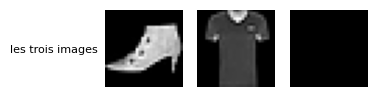

In [25]:
BOOT_14 = XF_TEST[np.flatnonzero(YF_TEST == 9)[0]]       # an ankle boot (class 9), 784 pixels in [0, 1]
SHIRT_14 = XF_TEST[np.flatnonzero(YF_TEST == 0)[0]]      # a T-shirt (class 0)
BLACK_14 = np.zeros(784, dtype=np.float32)               # an all-black image


def train_one_image_14(image, n_latent=20, bias=True, steps=500, seed=2514):
    """A 784-n_latent-784 autoencoder (Linear + ReLU, then Linear + Sigmoid), trained on ONE image only:
    `steps` steps of Adam (learning rate 0.001) on the binary cross-entropy. With bias=False, no layer has biases."""
    torch.manual_seed(seed)
    model = AutoEncoder(nn.Sequential(nn.Linear(784, n_latent, bias=bias), nn.ReLU()),
                        nn.Sequential(nn.Linear(n_latent, 784, bias=bias), nn.Sigmoid()))
    x = to_tensor(image).reshape(1, 784)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(steps):
        loss = F.binary_cross_entropy(model(x), x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model


show_rows([np.stack([BOOT_14, SHIRT_14, BLACK_14])], ["les trois images"], size=1.3)

In [26]:
black_14, shirt_14, no_bias_14 = False, True, True

In [27]:
wb.record("25.14a", False, mistakes={"regarde la colonne « noir → botte » : la sortie de l'image noire est-elle proche de la botte ?": True})
wb.record("25.14b", True, mistakes={"compare les colonnes « T-shirt → botte » et « T-shirt → T-shirt » : de quelle image la sortie est-elle la plus proche ?": False})
wb.record("25.14c", True, mistakes={"regarde la ligne « sans biais » : la botte est-elle encore reconstruite ?": False})

WB_ANSWER {"hash": "b34055c3796785e05fbd1ddb09ce6f34f1be5b1d86a10c5fc7fac5738442d0ff", "id": "25.14a", "kind": "bool", "mistakes": {"00f5d3a99b2fd9c9c0b62c0023133bb4d36149f804ed1d89c40efaa5d2dbef5e": "regarde la colonne « noir → botte » : la sortie de l'image noire est-elle proche de la botte ?"}}
📝 Ex 25.14a : réponse enregistrée (bool).
WB_ANSWER {"hash": "8b827a147f96c67737c6c1139a294e9d540e6da8cae1bfeb5d4d2e4656ca12b7", "id": "25.14b", "kind": "bool", "mistakes": {"abc82e1fa03ff1b96c0bf018309cb045043d777af966789a5506b7c9dc9c9821": "compare les colonnes « T-shirt → botte » et « T-shirt → T-shirt » : de quelle image la sortie est-elle la plus proche ?"}}
📝 Ex 25.14b : réponse enregistrée (bool).
WB_ANSWER {"hash": "945e3e7c4b3e692938bd903578f6f94902e4106e47a694724e82d0b46cc59716", "id": "25.14c", "kind": "bool", "mistakes": {"9a73b24fe3933532f1e6f91142b19f0271e1264bc4895555c85e4961f559769e": "regarde la ligne « sans biais » : la botte est-elle encore reconstruite ?"}}
📝 Ex 25.14c : r

              botte → botte  noir → botte  T-shirt → botte  T-shirt → T-shirt  code nul → botte
avec biais          0.00000        0.1703           0.0148             0.0863            0.1791
sans biais          0.00000        0.1922           0.0158             0.0850            0.1922


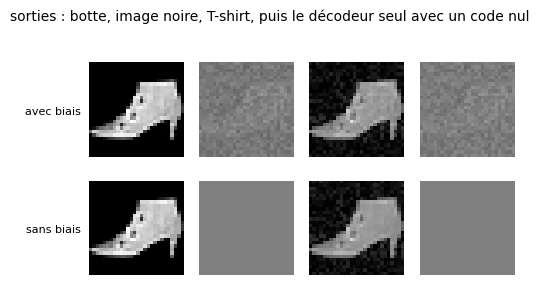

✅ Ex 25.14a : Bien joué !
✅ Ex 25.14b : C'est ça !
✅ Ex 25.14c : Parfait !


In [28]:
if any(answer is ... or answer is None for answer in [black_14, shirt_14, no_bias_14]):
    print("⏳ Ex 25.14 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    with checked("25.14"):
        models_14 = {"avec biais": train_one_image_14(BOOT_14), "sans biais": train_one_image_14(BOOT_14, bias=False)}
        print(f"{'':12s} {'botte → botte':>14s} {'noir → botte':>13s} {'T-shirt → botte':>16s} {'T-shirt → T-shirt':>18s} "
              f"{'code nul → botte':>17s}")
        rows_14, titles_14 = [], []
        for name_14, model_14 in models_14.items():
            out_14 = reconstruct(model_14, np.stack([BOOT_14, BLACK_14, SHIRT_14]))
            zero_code_14 = decode(model_14, np.zeros((1, 20), dtype=np.float32))[0]   # the decoder alone, code = 0
            print(f"{name_14:12s} {mse_per_image(out_14[:1], BOOT_14[None])[0]:14.5f} "
                  f"{mse_per_image(out_14[1:2], BOOT_14[None])[0]:13.4f} {mse_per_image(out_14[2:], BOOT_14[None])[0]:16.4f} "
                  f"{mse_per_image(out_14[2:], SHIRT_14[None])[0]:18.4f} {mse_per_image(zero_code_14[None], BOOT_14[None])[0]:17.4f}")
            rows_14.append(np.vstack([out_14, zero_code_14[None]]))
            titles_14.append(name_14)
        show_rows(rows_14, titles_14, "sorties : botte, image noire, T-shirt, puis le décodeur seul avec un code nul", size=1.3)
    wb.check("25.14a", black_14)
    wb.check("25.14b", shirt_14)
    wb.check("25.14c", no_bias_14)

Dans tes notes : lesquelles de tes prédictions étaient justes ? Pourquoi le T-shirt donne-t-il la botte alors que l'image noire ne la donne pas (regarde ce que la première couche fait d'une entrée nulle, puis la colonne « code nul ») ? Où ce réseau a-t-il rangé la botte : dans les biais de sa sortie, ou dans les poids de son décodeur ? Qu'est-ce qui, chez le livre, a pu ranger le tigre dans les biais ?

### Ex 25.15 — Premier autoencodeur dense 784-20-784 en PyTorch 📦 ★★ ⏱️ 25 min
**Objectif :** écrire le premier autoencodeur du livre et sa boucle d'entraînement, dont la cible est l'entrée elle-même.  
**Prérequis :** Ex 25.1 · ch. 23 (Ex 23.18, boucle d'entraînement) · fiche §25.3, §25.4 · **Fil rouge :** MNIST · **Parcours :** R, M, C

Le premier autoencodeur du livre sur MNIST : une couche dense de 784 vers 20 neurones avec une ReLU (l'encodeur), une couche de 20 vers 784 avec une sigmoïde (le décodeur), et une loss qui compare la sortie à l'**entrée**.

**Contrat**
- `make_dense_ae_15(n_latent=20)` rend un `AutoEncoder` dont l'encodeur est `nn.Sequential(nn.Linear(784, n_latent), nn.ReLU())` et le décodeur `nn.Sequential(nn.Linear(n_latent, 784), nn.Sigmoid())` ;
- `fit_ae_15(model, x, epochs, lr=1e-3, batch_size=128, seed=0)` entraîne `model` sur place : `x` est un tableau NumPy `float32` `(N, 784)` dans $[0, 1]$, l'optimiseur `Adam(lr)`, la loss la cross-entropy binaire **moyenne** entre `model(batch)` et le batch lui-même ; les mini-batches suivent un ordre tiré à chaque epoch par `torch.randperm(N, generator=g)`, avec **un seul** `g = torch.Generator().manual_seed(seed)` créé avant la première epoch ; les batches vont sur le device du modèle ; la fonction rend la liste des losses moyennes de chaque epoch (chaque batch pesé par sa taille).

La vérification regarde l'architecture et la sortie, puis entraîne deux fois trois epochs sur 1 024 images (la même graine doit donner les mêmes losses). La cellule suivante entraîne trois autoencodeurs, à 20, 10 et 3 latents (une dizaine de secondes en mode rapide), et affiche leurs reconstructions.

Dans tes notes : comment la qualité change-t-elle de 20 à 3 latents, et retrouves-tu ce que décrit la fiche (un 4 qui tourne au 9, des taches) ? Pourquoi une sigmoïde en sortie, et pourquoi la cross-entropy binaire convient-elle à des pixels qui ne sont pas des 0 et des 1 ?

In [29]:
def make_dense_ae_15(n_latent=20):
    """The book's first autoencoder: an AutoEncoder whose encoder is nn.Sequential(nn.Linear(784, n_latent),
    nn.ReLU()) and whose decoder is nn.Sequential(nn.Linear(n_latent, 784), nn.Sigmoid())."""
    return AutoEncoder(nn.Sequential(nn.Linear(784, n_latent), nn.ReLU()),
                       nn.Sequential(nn.Linear(n_latent, 784), nn.Sigmoid()))


def fit_ae_15(model, x, epochs, lr=1e-3, batch_size=128, seed=0):
    """Train `model` in place on the images x (a float32 NumPy array (N, 784) in [0, 1]) to give back its input:
    Adam(lr), the mean binary cross-entropy between model(batch) and the batch, mini-batches of `batch_size` in an
    order drawn each epoch by torch.randperm(N, generator=g), with ONE g = torch.Generator().manual_seed(seed) made
    before the first epoch. Returns the list of the mean losses of each epoch (each batch weighted by its size)."""
    device = next(model.parameters()).device
    x = to_tensor(x)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    losses = []
    model.train()
    for _ in range(epochs):
        order = torch.randperm(len(x), generator=g)
        total = 0.0
        for i in range(0, len(x), batch_size):
            xb = x[order[i:i + batch_size]].to(device)
            loss = F.binary_cross_entropy(model(xb), xb)        # the target is the input itself
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        losses.append(total / len(x))
    return losses


with checked("25.15"):
    torch.manual_seed(0)
    model_15 = make_dense_ae_15(20)
    if returned("25.15", "make_dense_ae_15", model_15):
        layers_15 = [type(m).__name__ for m in model_15.encoder] + ["|"] + [type(m).__name__ for m in model_15.decoder]
        verdict("25.15", isinstance(model_15, AutoEncoder) and layers_15 == ["Linear", "ReLU", "|", "Linear", "Sigmoid"],
                "make_dense_ae_15 : un AutoEncoder (Linear, ReLU | Linear, Sigmoid).",
                f"attendu AutoEncoder(Sequential(Linear, ReLU), Sequential(Linear, Sigmoid)), reçu {layers_15}.")
        shapes_15 = [(m.in_features, m.out_features) for m in model_15.modules() if isinstance(m, nn.Linear)]
        verdict("25.15", shapes_15 == [(784, 20), (20, 784)], "les deux couches font 784 → 20 et 20 → 784.",
                f"tailles des couches : attendu [(784, 20), (20, 784)], reçu {shapes_15}.")
        out_15 = reconstruct(model_15, X_MNIST[:5])
        verdict("25.15", out_15.shape == (5, 784) and out_15.min() >= 0 and out_15.max() <= 1,
                "une sortie (5, 784) dans [0, 1].", f"la sortie doit être (5, 784) dans [0, 1], reçu {out_15.shape}.")
    torch.manual_seed(0)
    losses_15 = fit_ae_15(make_dense_ae_15(20), X_MNIST[:1024], epochs=3, seed=1)
    if returned("25.15", "fit_ae_15", losses_15):
        torch.manual_seed(0)
        again_15 = fit_ae_15(make_dense_ae_15(20), X_MNIST[:1024], epochs=3, seed=1)
        verdict("25.15", len(losses_15) == 3 and np.allclose(losses_15, again_15, rtol=1e-5)
                and losses_15[2] < losses_15[0] < 0.75,
                f"fit_ae_15 : trois losses qui baissent ({', '.join(fr(v, 3) for v in losses_15)}), les mêmes à chaque appel.",
                f"attendu une loss par epoch, qui baisse et soit la même à chaque appel, reçu {losses_15!r:.200} puis "
                f"{again_15!r:.200} (un seul générateur, créé avant la première epoch ; la cible est l'entrée).")

✅ Ex 25.15 : make_dense_ae_15 : un AutoEncoder (Linear, ReLU | Linear, Sigmoid).
✅ Ex 25.15 : les deux couches font 784 → 20 et 20 → 784.
✅ Ex 25.15 : une sortie (5, 784) dans [0, 1].


✅ Ex 25.15 : fit_ae_15 : trois losses qui baissent (0,691, 0,668, 0,622), les mêmes à chaque appel.


20 latents : MSE de test 0.0434 (1.7 s)


10 latents : MSE de test 0.0607 (1.7 s)


 3 latents : MSE de test 0.0687 (1.8 s)


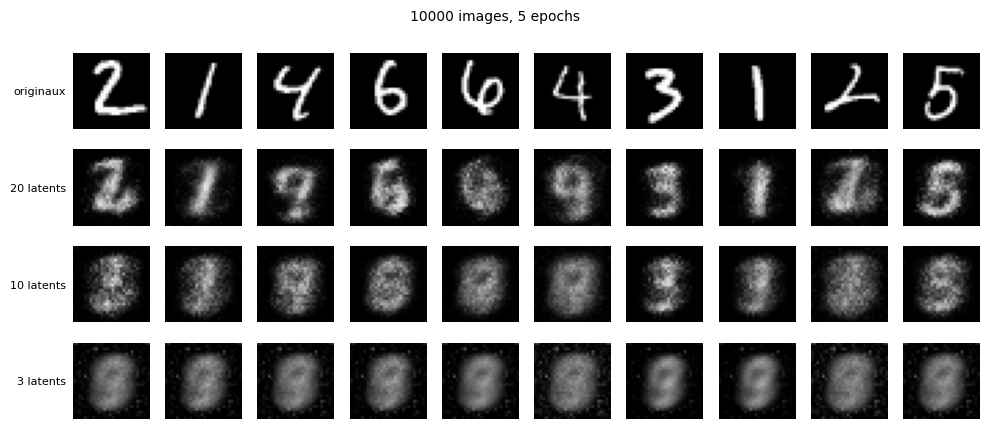

In [30]:
with checked("25.15"):
    EPOCHS_15 = 5 if FAST_MODE else 20
    results_15 = {}
    for n_latent_15 in (20, 10, 3):
        torch.manual_seed(2515)
        model_15 = make_dense_ae_15(n_latent_15).to(DEVICE)
        start_15 = time.perf_counter()
        fit_ae_15(model_15, X_MNIST, EPOCHS_15, seed=2515)
        results_15[n_latent_15] = (reconstruct(model_15, XM_TEST), time.perf_counter() - start_15)
        print(f"{n_latent_15:2d} latents : MSE de test {mse_per_image(results_15[n_latent_15][0], XM_TEST).mean():.4f} "
              f"({results_15[n_latent_15][1]:.1f} s)")
    show_rows([XM_TEST[:10]] + [results_15[n][0][:10] for n in (20, 10, 3)],
              ["originaux", "20 latents", "10 latents", "3 latents"], f"{len(X_MNIST)} images, {EPOCHS_15} epochs")

La cellule suivante donne les versions de référence de `make_dense_ae` et de la boucle, `train_ae`, qui rend aussi un historique : les exercices suivants s'en servent.

In [31]:
# From here on: the reference versions of make_dense_ae and of the training loop (your 25.15, plus a history)
def make_dense_ae(n_latent=20):
    """The autoencoder of 25.15: Linear(784, n_latent) + ReLU, then Linear(n_latent, 784) + Sigmoid."""
    return AutoEncoder(nn.Sequential(nn.Linear(784, n_latent), nn.ReLU()),
                       nn.Sequential(nn.Linear(n_latent, 784), nn.Sigmoid()))


def train_ae(model, x, epochs, lr=1e-3, batch_size=128, seed=0, loss="bce", x_val=None, verbose=False):
    """Train the autoencoder `model` in place (on DEVICE) to give back the images x (N, 784): Adam(lr), mini-batches
    in an order drawn from `seed`, the mean binary cross-entropy (loss="bce") or squared error (loss="mse").
    Returns the history: "loss" (mean of each epoch), "val_mse" (MSE of x_val after each epoch, if given),
    "seconds" (duration of each epoch)."""
    model.to(DEVICE)
    x = to_tensor(x)
    loss_fn = F.binary_cross_entropy if loss == "bce" else F.mse_loss
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    history = {"loss": [], "val_mse": [], "seconds": []}
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.train()
        total = 0.0
        order = torch.randperm(len(x), generator=g)
        for i in range(0, len(x), batch_size):
            xb = x[order[i:i + batch_size]].to(DEVICE)
            batch_loss = loss_fn(model(xb), xb)
            optimizer.zero_grad()
            batch_loss.backward()
            optimizer.step()
            total += batch_loss.item() * len(xb)
        history["loss"].append(total / len(x))
        history["seconds"].append(time.perf_counter() - start)
        if x_val is not None:
            history["val_mse"].append(float(mse_per_image(reconstruct(model, x_val), x_val).mean()))
        if verbose:
            print(f"epoch {epoch:2d} · loss {history['loss'][-1]:.4f}" +
                  (f" · val MSE {history['val_mse'][-1]:.4f}" if x_val is not None else ""))
    return history

### Ex 25.16 — Autoencodeur profond 512-256-128-20 📦 ★★ ⏱️ 25 min
**Objectif :** construire un autoencodeur profond symétrique et mesurer ce que la profondeur apporte à goulot égal.  
**Prérequis :** Ex 25.15 · fiche §25.4 · **Fil rouge :** MNIST · **Parcours :** R, M, C

Le livre passe à un autoencodeur **profond** : trois couches cachées de 512, 256 et 128 neurones avant le code, et le chemin inverse après. Ton code n'a pas d'activation : ses valeurs peuvent être négatives (le livre mettait une ReLU au goulot, d'où ses latents tous positifs).

**Contrat** : `make_deep_ae_16(n_latent=20, hidden=(512, 256, 128))` rend un `AutoEncoder` dont l'encodeur est `Linear(784, hidden[0])` + ReLU, `Linear(hidden[0], hidden[1])` + ReLU…, puis `Linear(hidden[-1], n_latent)` **sans** activation, et le décodeur le miroir : `Linear(n_latent, hidden[-1])` + ReLU…, `Linear(hidden[0], 784)` + sigmoïde ; encodeur et décodeur sont des `nn.Sequential`.

La vérification compare la suite des couches à celle attendue, pour deux réglages. La cellule suivante entraîne le dense de 25.15 et ton profond, avec le même `train_ae` (8 epochs en mode rapide, une quinzaine de secondes), et compare leurs erreurs de test.

Dans tes notes : combien de paramètres le profond a-t-il de plus, et que gagne-t-il ? Avec la fiche (« assez de latents et assez de capacité »), qu'est-ce qui limite chacun des deux modèles ?

In [32]:
def make_deep_ae_16(n_latent=20, hidden=(512, 256, 128)):
    """A deep autoencoder: the encoder is Linear(784, hidden[0]) + ReLU, Linear(hidden[0], hidden[1]) + ReLU, ...,
    then Linear(hidden[-1], n_latent) WITHOUT activation (the code can be negative); the decoder is the mirror
    image: Linear(n_latent, hidden[-1]) + ReLU, ..., Linear(hidden[0], 784) + Sigmoid. Returns an AutoEncoder
    whose encoder and decoder are nn.Sequential."""
    sizes = [784, *hidden, n_latent]
    encoder = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        encoder += [nn.Linear(n_in, n_out), nn.ReLU()]
    encoder.pop()                                       # no activation on the code
    back = sizes[::-1]                                  # n_latent, ..., 784
    decoder = []
    for n_in, n_out in zip(back[:-1], back[1:]):
        decoder += [nn.Linear(n_in, n_out), nn.ReLU()]
    decoder[-1] = nn.Sigmoid()                          # pixels in [0, 1]
    return AutoEncoder(nn.Sequential(*encoder), nn.Sequential(*decoder))


with checked("25.16"):
    torch.manual_seed(0)
    model_16 = make_deep_ae_16(20)
    if returned("25.16", "make_deep_ae_16", model_16):
        def _layout_16(seq):
            return [(m.in_features, m.out_features) if isinstance(m, nn.Linear) else type(m).__name__ for m in seq]
        want_enc_16 = [(784, 512), "ReLU", (512, 256), "ReLU", (256, 128), "ReLU", (128, 20)]
        want_dec_16 = [(20, 128), "ReLU", (128, 256), "ReLU", (256, 512), "ReLU", (512, 784), "Sigmoid"]
        verdict("25.16", _layout_16(model_16.encoder) == want_enc_16, "l'encodeur : 784 → 512 → 256 → 128 → 20, sans activation sur le code.",
                f"encodeur attendu {want_enc_16}, reçu {_layout_16(model_16.encoder)}.")
        verdict("25.16", _layout_16(model_16.decoder) == want_dec_16, "le décodeur : son miroir, terminé par une sigmoïde.",
                f"décodeur attendu {want_dec_16}, reçu {_layout_16(model_16.decoder)}.")
        other_16 = make_deep_ae_16(2, hidden=(64,))
        verdict("25.16", _layout_16(other_16.encoder) == [(784, 64), "ReLU", (64, 2)]
                and _layout_16(other_16.decoder) == [(2, 64), "ReLU", (64, 784), "Sigmoid"],
                "make_deep_ae_16(2, hidden=(64,)) suit aussi n_latent et hidden.",
                "make_deep_ae_16 doit suivre n_latent et hidden (essayé avec 2 et (64,)).")

✅ Ex 25.16 : l'encodeur : 784 → 512 → 256 → 128 → 20, sans activation sur le code.
✅ Ex 25.16 : le décodeur : son miroir, terminé par une sigmoïde.
✅ Ex 25.16 : make_deep_ae_16(2, hidden=(64,)) suit aussi n_latent et hidden.


dense 784-20-784            32,164 paramètres · MSE de test 0.0396 · 2.6 s


profond 512-256-128-20   1,138,212 paramètres · MSE de test 0.0271 · 11.1 s
✅ Ex 25.16 : à 20 latents, le profond reconstruit mieux que le dense.


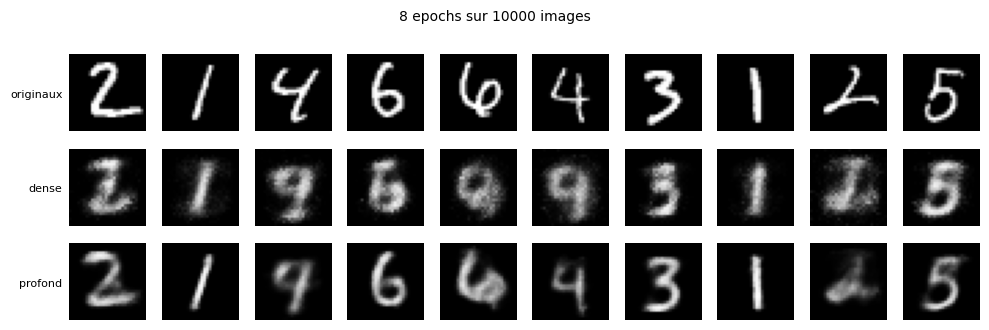

In [33]:
with checked("25.16"):
    EPOCHS_16 = 8 if FAST_MODE else 20
    histories_16 = {}
    for name_16, maker_16 in {"dense 784-20-784": make_dense_ae, "profond 512-256-128-20": make_deep_ae_16}.items():
        torch.manual_seed(2516)
        model_16 = maker_16(20)
        histories_16[name_16] = (model_16, train_ae(model_16, X_MNIST, EPOCHS_16, seed=2516, x_val=XM_TEST))
        print(f"{name_16:24s} {n_params(model_16):9,d} paramètres · MSE de test {histories_16[name_16][1]['val_mse'][-1]:.4f} "
              f"· {sum(histories_16[name_16][1]['seconds']):.1f} s")
    mse_dense_16, mse_deep_16 = (h["val_mse"][-1] for _, h in histories_16.values())
    verdict("25.16", mse_deep_16 < mse_dense_16, "à 20 latents, le profond reconstruit mieux que le dense.",
            "le profond devrait battre le dense à 20 latents : vérifie ton architecture.")
    show_rows([XM_TEST[:10]] + [reconstruct(m, XM_TEST[:10]) for m, _ in histories_16.values()],
              ["originaux", "dense", "profond"], f"{EPOCHS_16} epochs sur {len(X_MNIST)} images")

In [34]:
# The reference deep autoencoder (your 25.16), and AE_DEEP: the one that parts A and C explore (25.17 to 25.21,
# 25.31), trained the same way in both modes (the first N_FIXED images, 8 epochs, seed 2516; about 10 s on a CPU)
def make_deep_ae(n_latent=20, hidden=(512, 256, 128)):
    """The deep autoencoder of 25.16: dense ReLU layers, a linear code, a sigmoid output."""
    sizes = [784, *hidden, n_latent]
    encoder, decoder = [], []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        encoder += [nn.Linear(n_in, n_out), nn.ReLU()]
    for n_in, n_out in zip(sizes[::-1][:-1], sizes[::-1][1:]):
        decoder += [nn.Linear(n_in, n_out), nn.ReLU()]
    return AutoEncoder(nn.Sequential(*encoder[:-1]), nn.Sequential(*decoder[:-1], nn.Sigmoid()))


torch.manual_seed(2516)
AE_DEEP = make_deep_ae(20)
train_ae(AE_DEEP, X_MNIST[:N_FIXED], 8, seed=2516)
print(f"AE_DEEP : MSE de test {mse_per_image(reconstruct(AE_DEEP, XM_TEST), XM_TEST).mean():.4f}")

AE_DEEP : MSE de test 0.0271


### Ex 25.17 — Prédire : ce qu'un autoencodeur de chiffres fait d'un vêtement 🔮 ★★ ⏱️ 15 min
**Objectif :** prédire, puis mesurer, l'erreur d'un autoencodeur sur des entrées d'un autre domaine que ses données.  
**Prérequis :** Ex 25.16 · 25.Q11 · fiche §25.5.4, §25.7.2 · **Fil rouge :** Fashion-MNIST · **Parcours :** C

La fiche le dit : un autoencodeur de chiffres ne sait redessiner que des morceaux de chiffres. Mais de combien se trompe-t-il, et sur quels vêtements ? `AE_DEEP` (l'autoencodeur profond à 20 latents de la cellule précédente, entraîné sur des chiffres seulement) reçoit les 2 000 vêtements de test.

**Avant d'exécuter**, écris tes prédictions :
a) la MSE moyenne des vêtements divisée par celle des chiffres de test : `"A"` moins de 2, `"B"` entre 2 et 5, `"C"` plus de 5 ;
b) les **deux** classes de vêtements les mieux reconstruites (MSE moyennes les plus petites) : `"A"` Trouser et Dress (pantalon et robe), `"B"` Sandal et Sneaker (sandale et basket), `"C"` Bag et Ankle boot (sac et bottine), `"D"` T-shirt/top et Pullover ;
c) la MSE moyenne des vêtements est-elle plus petite que celle d'une réponse toute noire (0 partout) ? (`True` ou `False`)

In [35]:
ratio_17, best_17, black_17 = "B", "B", True

In [36]:
wb.record("25.17a", "B", mistakes={"calcule le rapport des deux MSE moyennes affichées : il est plus grand que 2": "A", "calcule le rapport des deux MSE moyennes affichées : il reste sous 5": "C"})
wb.record("25.17b", "B", mistakes={"relis le tableau par classe, trié de la meilleure à la pire reconstruction : ce ne sont pas les deux premières": "A", "relis le tableau par classe : ces deux classes sont en bas, pas en haut": "C", "relis le tableau par classe, trié de la meilleure à la pire : ces deux-là sont au milieu": "D"})
wb.record("25.17c", True, mistakes={"compare la MSE moyenne des vêtements à celle de l'image noire": False})

WB_ANSWER {"hash": "33b175e0a33fc34993bdefd4ad01989e2860efae85ffe61a1453be018e33d6bf", "id": "25.17a", "kind": "str", "mistakes": {"862ce254e140feca5f05c20e1f2f3f473d3ac5fcbbbca34406d14c4c81438906": "calcule le rapport des deux MSE moyennes affichées : il reste sous 5", "a76f32aef19c0b0f109a78911c6be02ebac045139b0d497ba1f3e5f9ab08502d": "calcule le rapport des deux MSE moyennes affichées : il est plus grand que 2"}}
📝 Ex 25.17a : réponse enregistrée (str).
WB_ANSWER {"hash": "ba867e91f7e17d09d873fc7be3093ad036a309ebb8b557e6175aafade292787d", "id": "25.17b", "kind": "str", "mistakes": {"11f9cec1637c30ba8192686809b40a44605b9255521b1b79d9ed5f695526a51f": "relis le tableau par classe, trié de la meilleure à la pire reconstruction : ce ne sont pas les deux premières", "42f110e8c5712845c8c88896e15aa795c19a1139a11cf2b82cabf557b3ce1df6": "relis le tableau par classe, trié de la meilleure à la pire : ces deux-là sont au milieu", "d773d79edf690891f5f52cffe2ea9d18e7586e2df2990dfd902509964d441322"

MSE moyenne · chiffres 0.0271 · vêtements 0.0924 (rapport 3.41) · image noire sur les vêtements 0.2070
  Sandal       0.0549
  Sneaker      0.0562
  Dress        0.0787
  Trouser      0.0814
  Shirt        0.0928
  Coat         0.1018
  T-shirt/top  0.1026
  Pullover     0.1033
  Ankle boot   0.1171
  Bag          0.1308


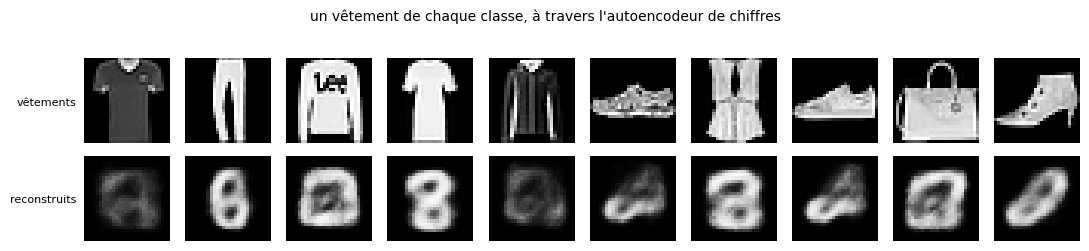

✅ Ex 25.17a : Bravo !
✅ Ex 25.17b : Exact !
✅ Ex 25.17c : Bien joué !


In [37]:
if any(answer is ... or answer is None for answer in [ratio_17, best_17, black_17]):
    print("⏳ Ex 25.17 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    with checked("25.17"):
        mse_digits_17 = mse_per_image(reconstruct(AE_DEEP, XM_TEST), XM_TEST)
        out_clothes_17 = reconstruct(AE_DEEP, XF_TEST)
        mse_clothes_17 = mse_per_image(out_clothes_17, XF_TEST)
        mse_black_17 = mse_per_image(np.zeros_like(XF_TEST), XF_TEST)
        print(f"MSE moyenne · chiffres {mse_digits_17.mean():.4f} · vêtements {mse_clothes_17.mean():.4f} "
              f"(rapport {mse_clothes_17.mean() / mse_digits_17.mean():.2f}) · image noire sur les vêtements {mse_black_17.mean():.4f}")
        for c_17 in np.argsort([mse_clothes_17[YF_TEST == c].mean() for c in range(10)]):
            print(f"  {FASHION_CLASSES[c_17]:12s} {mse_clothes_17[YF_TEST == c_17].mean():.4f}")
        first_17 = [np.flatnonzero(YF_TEST == c)[0] for c in range(10)]
        show_rows([XF_TEST[first_17], out_clothes_17[first_17]], ["vêtements", "reconstruits"],
                  "un vêtement de chaque classe, à travers l'autoencodeur de chiffres", size=1.1)
    wb.check("25.17a", ratio_17)
    wb.check("25.17b", best_17)
    wb.check("25.17c", black_17)

Dans tes notes : qu'ont en commun les vêtements les mieux reconstruits, et à quels chiffres ressemblent leurs reconstructions ? Que t'apprend c) sur ce que l'autoencodeur a quand même appris des images en général ? Quel usage pratique tire-t-on de cet écart d'erreur (25.37) ?

### Ex 25.18 — Reproduire la carte latente 2D et sa grille décodée (fig. 25.29-25.30) 🎨 ★★ ⏱️ 30 min
**Objectif :** dessiner l'espace latent d'un autoencodeur à 2 latents et décoder une grille de codes.  
**Prérequis :** Ex 25.16 · fiche §25.5.2 · **Fil rouge :** MNIST · **Parcours :** C

Le livre réduit chaque chiffre à **deux** nombres, place les codes de 10 000 chiffres sur un plan (fig. 25.29), puis décode une grille régulière de codes (fig. 25.30). La cellule donnée entraîne `AE_2D`, l'autoencodeur profond de 25.16 avec un code de 2 nombres.

**Contrat**
- `grid_codes_18(lims, n)` rend les $n \times n$ codes d'une grille régulière sur `lims = (xmin, xmax, ymin, ymax)`, en tableau `(n * n, 2)`, ligne par ligne **comme dans une image** : la première ligne a $y$ = `ymax` (le haut), la dernière $y$ = `ymin` ; dans chaque ligne, $x$ va de `xmin` à `xmax` ; les deux bords sont inclus ;
- `plot_latent_map_18(model, x, labels, n=15)` trace deux panneaux côte à côte : à gauche, les codes de `x` en points, colorés par chiffre (`labels`), avec une légende ; à droite, les $n \times n$ images décodées de `grid_codes_18` sur les **mêmes limites** que le panneau de gauche (le min et le max des codes), assemblées en **une** image de $28n \times 28n$ pixels, le code du coin en haut à gauche en premier ; elle finit par `plt.show()` et rend cette mosaïque.

La vérification essaie `grid_codes_18` sur une petite grille, puis trace la carte des 2 000 chiffres de test et compare le coin en haut à gauche de ta mosaïque au décodage de son code.

Dans tes notes : quels chiffres ont des régions bien à eux, lesquels se chevauchent ? Où sont les zones vides, et que décode la grille à ces endroits ? Pourquoi est-ce un problème pour générer des chiffres en tirant des codes au hasard ?

In [38]:
# AE_2D: a deep autoencoder with a code of 2 numbers, trained on the first N_FIXED images (10 epochs, ≈ 12 s)
torch.manual_seed(2518)
AE_2D = make_deep_ae(2)
train_ae(AE_2D, X_MNIST[:N_FIXED], 10, seed=2518)
print(f"AE_2D : MSE de test {mse_per_image(reconstruct(AE_2D, XM_TEST), XM_TEST).mean():.4f}")

AE_2D : MSE de test 0.0423


✅ Ex 25.18 : grid_codes_18((0, 1, -2, 2), 3) : un tableau (9, 2), comme attendu.


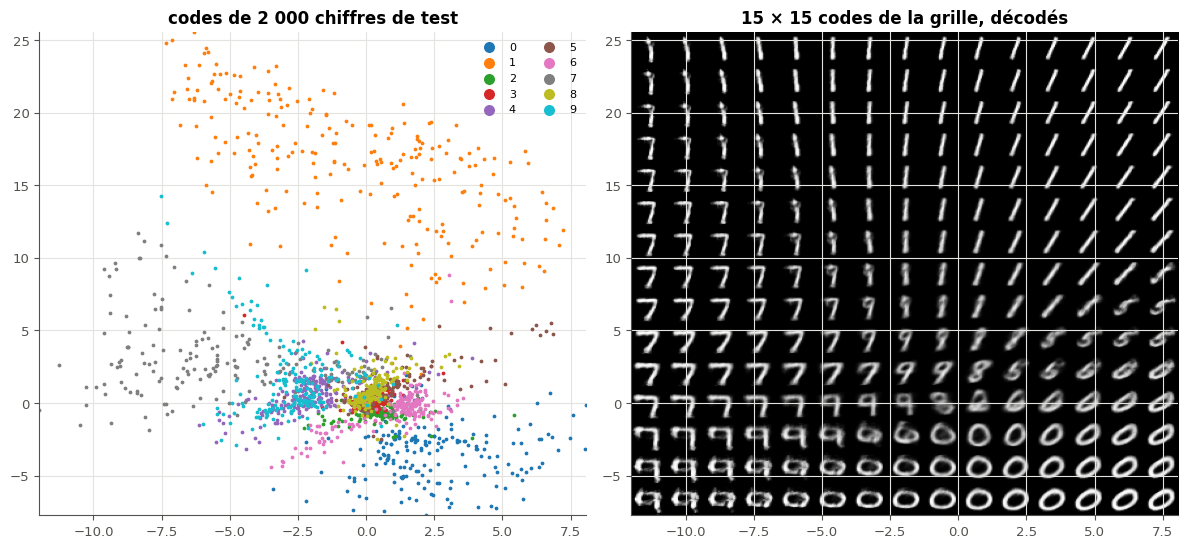

✅ Ex 25.18 : la mosaïque (420, 420) commence par le code du coin en haut à gauche (x min, y max).


In [39]:
def grid_codes_18(lims, n):
    """The n × n codes of a regular grid over lims = (xmin, xmax, ymin, ymax), as an array (n * n, 2), row by row
    as in an image: the first row has y = ymax (the top), the last y = ymin; in each row, x goes from xmin to xmax.
    Both ends are included (np.linspace)."""
    xmin, xmax, ymin, ymax = lims
    xs, ys = np.linspace(xmin, xmax, n), np.linspace(ymax, ymin, n)       # y from the top to the bottom
    gx, gy = np.meshgrid(xs, ys)                                          # gx[i, j] = xs[j], gy[i, j] = ys[i]
    return np.column_stack([gx.ravel(), gy.ravel()])


def plot_latent_map_18(model, x, labels, n=15):
    """Two panels side by side: (left) the codes model.encoder(x) as points (x, y), coloured by digit (labels),
    with a legend; (right) the n × n images decoded from grid_codes_18 over the same limits as the left panel
    (the min and max of the codes), assembled in ONE image of (28 n) × (28 n) pixels, the code of the top-left
    corner first. Ends with plt.show(). Returns the mosaic (an array (28 n, 28 n))."""
    codes = encode(model, x)
    lims = (codes[:, 0].min(), codes[:, 0].max(), codes[:, 1].min(), codes[:, 1].max())
    images = decode(model, grid_codes_18(lims, n).astype(np.float32)).reshape(n, n, 28, 28)
    mosaic = images.transpose(0, 2, 1, 3).reshape(28 * n, 28 * n)        # rows of images, then rows of pixels
    fig, (ax_map, ax_grid) = plt.subplots(1, 2, figsize=(12, 5.6))
    colors = wb.plot.class_colors(10)
    for digit in range(10):
        keep = np.asarray(labels) == digit
        ax_map.scatter(codes[keep, 0], codes[keep, 1], s=3, color=colors[digit], label=str(digit))
    ax_map.set_xlim(lims[0], lims[1])
    ax_map.set_ylim(lims[2], lims[3])
    ax_map.legend(markerscale=4, fontsize=8, ncol=2)
    ax_map.set_title("codes de 2 000 chiffres de test")
    ax_grid.imshow(mosaic, cmap="gray", extent=lims, aspect="auto")
    ax_grid.set_title(f"{n} × {n} codes de la grille, décodés")
    plt.tight_layout()
    plt.show()
    return mosaic


with checked("25.18"):
    grid_18 = grid_codes_18((0.0, 1.0, -2.0, 2.0), 3)
    if returned("25.18", "grid_codes_18", grid_18):
        same("25.18", "grid_codes_18((0, 1, -2, 2), 3)", grid_18,
             [[0, 2], [0.5, 2], [1, 2], [0, 0], [0.5, 0], [1, 0], [0, -2], [0.5, -2], [1, -2]])
    mosaic_18 = plot_latent_map_18(AE_2D, XM_TEST, YM_TEST, n=15)
    if returned("25.18", "plot_latent_map_18", mosaic_18):
        codes_18 = encode(AE_2D, XM_TEST)
        corner_18 = decode(AE_2D, np.array([[codes_18[:, 0].min(), codes_18[:, 1].max()]], dtype=np.float32))
        verdict("25.18", np.shape(mosaic_18) == (420, 420) and np.allclose(np.asarray(mosaic_18)[:28, :28],
                                                                           corner_18.reshape(28, 28), atol=1e-5),
                "la mosaïque (420, 420) commence par le code du coin en haut à gauche (x min, y max).",
                f"attendu une mosaïque (420, 420) dont l'image en haut à gauche décode (x min, y max), reçu "
                f"{shape_text(mosaic_18)} (transpose(0, 2, 1, 3) avant le reshape).")

### Ex 25.19 — Secouer les variables latentes : bruit global, une seule composante, latents aléatoires 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer la tolérance du décodeur à un bruit sur les codes, latent par latent, et le décodage de codes au hasard.  
**Prérequis :** Ex 25.16 · fiche §25.5, §25.5.1 · **Fil rouge :** MNIST · **Parcours :** C

Le livre secoue les 20 latents de ses chiffres avec des bruits uniformes de plus en plus forts, puis un seul latent à la fois, puis remplace les codes par des nombres au hasard. Tu refais les trois expériences sur `AE_DEEP` ; comme ses latents n'ont pas l'échelle de ceux du livre, les bruits sont comptés en **écarts-types** des latents.

**Contrat**
- `add_noise_19(codes, scale, rng, column=None)` rend un **nouveau** tableau : `codes` `(N, d)` plus un bruit uniforme dans $[-\text{scale}, \text{scale}]$, tiré par `rng.uniform(-scale, scale, size=...)`, sur toutes les valeurs (`size=codes.shape`) si `column` vaut `None`, sinon sur cette colonne seulement (`size=N`) ; `codes` n'est pas modifié ;
- `noise_mse_19(model, x, scales, seed=0, column=None)` : pour chaque valeur de `scales`, les codes `encode(model, x)`, bruités par `add_noise_19(..., scale, np.random.default_rng(seed), column)` (un **nouveau** générateur pour chaque valeur), puis décodés ; elle rend la liste des MSE moyennes entre ces images et `x`.

La vérification compare tes bruits à ceux d'un générateur de même graine. La cellule suivante trace l'erreur selon le bruit, puis l'erreur quand un seul latent est bruité (un diagramme en barres), et décode des codes tirés au hasard entre le min et le max de chaque latent.

Dans tes notes : à partir de quel bruit les chiffres deviennent-ils illisibles ? Les latents comptent-ils tous autant ? Que donnent les codes au hasard, et pourquoi (25.18) ?

In [40]:
def add_noise_19(codes, scale, rng, column=None):
    """A new array: codes (N, d) plus uniform noise in [-scale, scale], drawn by rng.uniform(-scale, scale, size=...):
    on every value (size = codes.shape) if column is None, otherwise on that column only (size = N, the other
    columns unchanged). `codes` is not modified."""
    noisy = np.array(codes, dtype=np.float32)               # a copy
    if column is None:
        noisy += rng.uniform(-scale, scale, size=noisy.shape)
    else:
        noisy[:, column] += rng.uniform(-scale, scale, size=len(noisy))
    return noisy


def noise_mse_19(model, x, scales, seed=0, column=None):
    """For each scale of `scales`: the codes encode(model, x), plus add_noise_19(..., scale,
    np.random.default_rng(seed), column) (a NEW generator for each scale), decoded; returns the list of the mean
    MSE between these decoded images and x."""
    codes = encode(model, x)
    return [float(mse_per_image(decode(model, add_noise_19(codes, s, np.random.default_rng(seed), column)), x).mean())
            for s in scales]


with checked("25.19"):
    toy_19 = np.arange(6, dtype=np.float32).reshape(3, 2)
    noisy_19 = add_noise_19(toy_19, 0.5, np.random.default_rng(1))
    if returned("25.19", "add_noise_19", noisy_19):
        same("25.19", "add_noise_19(toy, 0.5, default_rng(1)) : tout le tableau",
             noisy_19, toy_19 + np.random.default_rng(1).uniform(-0.5, 0.5, size=(3, 2)), rtol=1e-6, atol=1e-6)
        same("25.19", "add_noise_19(toy, 0.5, default_rng(1), column=1) : la colonne 1 seulement",
             add_noise_19(toy_19, 0.5, np.random.default_rng(1), column=1),
             np.column_stack([toy_19[:, 0], toy_19[:, 1] + np.random.default_rng(1).uniform(-0.5, 0.5, size=3)]),
             rtol=1e-6, atol=1e-6)
        verdict("25.19", np.array_equal(toy_19, np.arange(6).reshape(3, 2)), "codes n'est pas modifié.",
                "add_noise_19 a modifié son entrée : travaille sur une copie.")
    mse_19 = noise_mse_19(AE_DEEP, XM_TEST[:200], [0.0, 1.0])
    if returned("25.19", "noise_mse_19", mse_19):
        clean_19 = mse_per_image(reconstruct(AE_DEEP, XM_TEST[:200]), XM_TEST[:200]).mean()
        verdict("25.19", len(mse_19) == 2 and abs(mse_19[0] - clean_19) < 1e-6 and mse_19[1] > mse_19[0],
                "noise_mse_19 : un bruit nul redonne l'erreur de reconstruction, un bruit de 1 l'augmente.",
                f"attendu [MSE sans bruit = {clean_19:.4f}, une valeur plus grande], reçu {mse_19!r:.200}.")

✅ Ex 25.19 : add_noise_19(toy, 0.5, default_rng(1)) : tout le tableau : [[0.01182162, 1.45046365], [1.64415956, 3.44864941], [3.81183147, 4.92332649]], comme attendu.
✅ Ex 25.19 : add_noise_19(toy, 0.5, default_rng(1), column=1) : la colonne 1 seulement : [[0.0, 1.01182163], [2.0, 3.45046377], [4.0, 4.64415979]], comme attendu.
✅ Ex 25.19 : codes n'est pas modifié.
✅ Ex 25.19 : noise_mse_19 : un bruit nul redonne l'erreur de reconstruction, un bruit de 1 l'augmente.


écart-type des latents : 3.46 ; leurs valeurs vont de -12.6 à 11.3
bruit de ± 0.0 écart-type sur tous les latents : MSE 0.0271
bruit de ± 0.1 écart-type sur tous les latents : MSE 0.0275
bruit de ± 0.3 écart-type sur tous les latents : MSE 0.0307
bruit de ± 1.0 écart-type sur tous les latents : MSE 0.0538
bruit de ± 3.0 écart-type sur tous les latents : MSE 0.1026


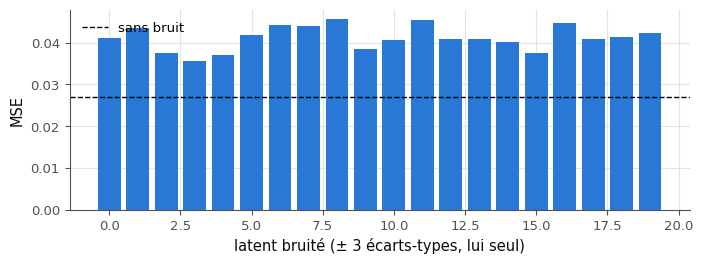

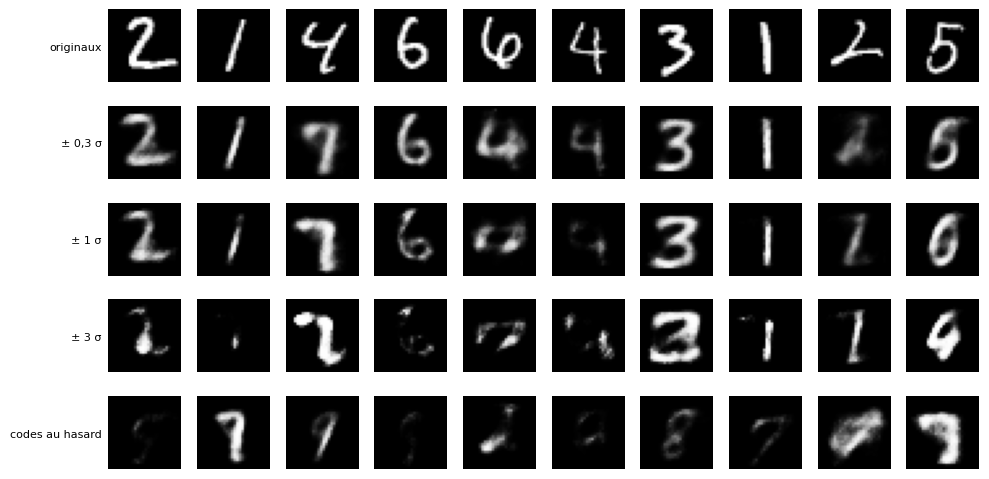

In [41]:
with checked("25.19"):
    codes_19 = encode(AE_DEEP, XM_TEST)
    spread_19 = float(codes_19.std())                      # the typical spread of a latent value
    rel_19 = (0.0, 0.1, 0.3, 1.0, 3.0)
    curve_19 = noise_mse_19(AE_DEEP, XM_TEST, [r * spread_19 for r in rel_19], seed=19)
    print(f"écart-type des latents : {spread_19:.2f} ; leurs valeurs vont de {codes_19.min():.1f} à {codes_19.max():.1f}")
    for r_19, m_19 in zip(rel_19, curve_19):
        print(f"bruit de ± {r_19:.1f} écart-type sur tous les latents : MSE {m_19:.4f}")
    one_19 = [noise_mse_19(AE_DEEP, XM_TEST, [3 * spread_19], seed=19, column=j)[0] for j in range(codes_19.shape[1])]
    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.bar(range(len(one_19)), one_19)
    ax.axhline(curve_19[0], color="k", lw=1, ls="--", label="sans bruit")
    ax.set_xlabel("latent bruité (± 3 écarts-types, lui seul)")
    ax.set_ylabel("MSE")
    ax.legend()
    plt.show()
    rng_19 = np.random.default_rng(1919)
    random_19 = rng_19.uniform(codes_19.min(axis=0), codes_19.max(axis=0), size=(10, codes_19.shape[1])).astype(np.float32)
    rows_19 = [XM_TEST[:10]] + [decode(AE_DEEP, add_noise_19(codes_19[:10], r * spread_19, np.random.default_rng(19)))
                                for r in (0.3, 1.0, 3.0)] + [decode(AE_DEEP, random_19)]
    show_rows(rows_19, ["originaux", "± 0,3 σ", "± 1 σ", "± 3 σ", "codes au hasard"])

### Ex 25.20 — Interpoler entre deux codes : linéaire et sphérique 🔨 ★★ ⏱️ 20 min
**Objectif :** écrire l'interpolation linéaire et sphérique (slerp) de deux codes dans ta librairie.  
**Prérequis :** Ex 25.6 · fiche §25.5.3 (encadré slerp) · **mylearn :** `vae.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/vae.py` (créé par `python tools/start_chapter.py 25`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur quelques cas ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_ch25_vae.py -q` les lance tous dans un terminal.

**Contrat commun de `vae.py`** (les docstrings, plus ces précisions que vérifient les tests) : les entrées peuvent être des listes et ne sont jamais modifiées ; chaque tableau rendu est un **nouveau** tableau `float64`, jamais une vue d'une entrée (même quand il lui est égal) ; une entrée qui contient un NaN lève `ValueError`.

Écris `interpolate_latents(z0, z1, n_steps, method="linear")` dans `vae.py`. **Contrat** propre à cette fonction :
- `z0` et `z1` sont deux vecteurs 1-D de même forme, sinon `ValueError` ; `n_steps` est un entier ≥ 2 (un `bool` ou un flottant sont refusés), `method` vaut `"linear"` ou `"slerp"`, sinon `ValueError` ;
- les valeurs de $t$ sont `np.linspace(0, 1, n_steps)`, et la fonction rend un tableau `(n_steps, d)` dont la première ligne est **exactement** `z0` et la dernière **exactement** `z1` ;
- `"linear"` : $(1 - t)\,\mathbf{z}_0 + t\,\mathbf{z}_1$ ; `"slerp"` : la formule de la fiche, avec $\Omega$ l'angle entre les deux vecteurs, qui s'applique à des vecteurs de **normes quelconques** ; elle revient à la ligne droite quand une norme est nulle ou quand $\sin\Omega$ est de l'ordre des erreurs d'arrondi (vecteurs parallèles ou opposés), sans émettre de `RuntimeWarning` : teste ces cas **avant** de diviser.

La cellule ci-dessous prend les codes d'un 1 et d'un 0 dans l'espace latent de `AE_DEEP`. La première cellule de vérification essaie ta fonction sur une ligne droite et un quart de cercle, puis décode les deux chemins du 1 au 0 et affiche la norme des codes en route. La seconde lance les tests (`-k "test_interpolate_latents_"`).

Dans tes notes : la norme des codes reste-t-elle constante le long du slerp, et le long de la ligne droite ? Ici, les images des deux chemins se ressemblent-elles ? Dans quel espace latent la différence devrait-elle compter le plus (fiche, et 25.Q9) ?

✅ Ex 25.20 : interpolate_latents((0, 0), (1, 2), 3) : la ligne droite : [[0.0, 0.0], [0.5, 1.0], [1.0, 2.0]], comme attendu.
✅ Ex 25.20 : slerp de (2, 0, 0) à (0, 2, 0) en 4 étapes : l'arc de cercle de rayon 2 : un tableau (4, 3), comme attendu.
normes des codes, ligne droite : [23.2 19.6 16.3 13.6 11.7 11.2 12.2 14.5]
normes des codes, slerp        : [23.2 23.2 22.3 20.6 18.5 16.3 14.8 14.5]


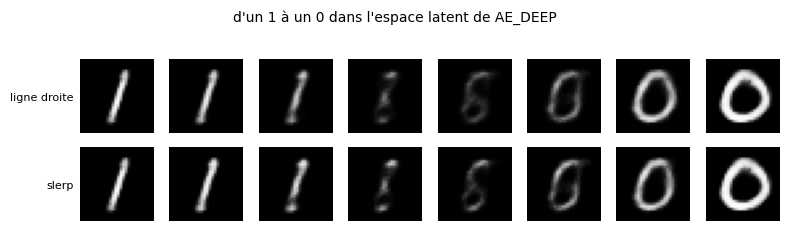

In [42]:
# Nothing to write here: interpolate_latents goes in mon_travail/mylearn/vae.py
z0_20 = encode(AE_DEEP, XM_TEST[np.flatnonzero(YM_TEST == 1)[:1]])[0]    # the code of a 1 ...
z1_20 = encode(AE_DEEP, XM_TEST[np.flatnonzero(YM_TEST == 0)[:1]])[0]    # ... and that of a 0

with checked("25.20"):
    V = mylearn.vae
    a_20, b_20 = np.array([0.0, 0.0]), np.array([1.0, 2.0])
    same("25.20", "interpolate_latents((0, 0), (1, 2), 3) : la ligne droite", V.interpolate_latents(a_20, b_20, 3),
         [[0, 0], [0.5, 1], [1, 2]])
    u_20, w_20 = np.array([2.0, 0.0, 0.0]), np.array([0.0, 2.0, 0.0])
    t_20 = np.linspace(0, 1, 4)[:, None]
    same("25.20", "slerp de (2, 0, 0) à (0, 2, 0) en 4 étapes : l'arc de cercle de rayon 2",
         V.interpolate_latents(u_20, w_20, 4, method="slerp"),
         np.sin((1 - t_20) * np.pi / 2) * u_20 + np.sin(t_20 * np.pi / 2) * w_20)
    path_lin_20 = V.interpolate_latents(z0_20, z1_20, 8)
    path_slerp_20 = V.interpolate_latents(z0_20, z1_20, 8, method="slerp")
    print("normes des codes, ligne droite :", np.round(np.linalg.norm(path_lin_20, axis=1), 1))
    print("normes des codes, slerp        :", np.round(np.linalg.norm(path_slerp_20, axis=1), 1))
    show_rows([decode(AE_DEEP, np.asarray(path_lin_20, dtype=np.float32)),
               decode(AE_DEEP, np.asarray(path_slerp_20, dtype=np.float32))], ["ligne droite", "slerp"],
              "d'un 1 à un 0 dans l'espace latent de AE_DEEP")

In [43]:
if written(lambda: mylearn.vae.interpolate_latents([0.0], [1.0], 2)):
    run_pytest_group(TEST_VAE, impl="ref", keyword="test_interpolate_latents_")
else:
    print("⏳ Ex 25.20 : les tests attendent tes fonctions.")

pytest: 21 passed, 65 deselected in 1.46s


### Ex 25.21 — Mélanger dans l'espace des pixels ou dans l'espace latent 🔬 ★★ ⏱️ 25 min
**Objectif :** comparer un fondu de pixels à une interpolation de codes, et mesurer à quel point chaque étape est « un chiffre ».  
**Prérequis :** Ex 25.20 · Ex 25.16 · ✏️ 25.2 · fiche §25.2.3, §25.5.3 · **Fil rouge :** MNIST · **Parcours :** R, C

Le ✏️ 25.2 opposait le mélange de contenu (les pixels) au mélange paramétrique. Un autoencodeur donne des « paramètres » appris : ses codes. Tu compares trois façons de passer d'un chiffre à un autre, en sept étapes : le fondu des pixels, la ligne droite entre les codes, le slerp entre les codes.

**Contrat**
- `blend_pixels_21(x0, x1, n_steps)` rend les images $(1 - t)\,\mathbf{x}_0 + t\,\mathbf{x}_1$ pour $t$ = `np.linspace(0, 1, n_steps)`, un tableau `(n_steps, 784)` ;
- `blend_codes_21(model, x0, x1, n_steps, method="linear")` encode `x0` et `x1`, interpole leurs codes avec **ta** `mylearn.vae.interpolate_latents(..., n_steps, method=method)` et décode : un tableau `(n_steps, 784)` ;
- `off_manifold_21(model, images)` rend, pour chaque image, la MSE entre elle et sa reconstruction par `model` : une mesure de « ce que l'autoencodeur ne sait pas redessiner ».

La vérification essaie tes trois fonctions sur des cas connus. La cellule suivante montre les trois mélanges d'un 1 à un 0, puis entre deux 5 différents, et affiche pour chaque étape la distance à ce que l'autoencodeur sait refaire.

Dans tes notes : à mi-chemin, laquelle des trois images ressemble le plus à un chiffre, et que disent les distances ? Pourquoi les étapes d'un fondu de pixels sont-elles, elles, « loin » de ce que l'autoencodeur sait refaire ? Le mélange de deux 5 se passe-t-il mieux que celui d'un 1 et d'un 0, et pourquoi ?

In [44]:
def blend_pixels_21(x0, x1, n_steps):
    """The images (1 - t) x0 + t x1 for t = np.linspace(0, 1, n_steps): an array (n_steps, 784)."""
    t = np.linspace(0, 1, n_steps)[:, None]
    return (1 - t) * np.asarray(x0, dtype=np.float32) + t * np.asarray(x1, dtype=np.float32)


def blend_codes_21(model, x0, x1, n_steps, method="linear"):
    """Encode x0 and x1, interpolate their codes with mylearn.vae.interpolate_latents(..., n_steps, method=method),
    and decode: an array (n_steps, 784)."""
    z0, z1 = encode(model, np.stack([x0, x1]))
    path = mylearn.vae.interpolate_latents(z0, z1, n_steps, method=method)
    return decode(model, np.asarray(path, dtype=np.float32))


def off_manifold_21(model, images):
    """How far each image is from what the autoencoder can redraw: the MSE between each image and its
    reconstruction, an array of len(images) values."""
    images = np.asarray(images, dtype=np.float32).reshape(len(images), -1)
    return mse_per_image(reconstruct(model, images), images)


with checked("25.21"):
    toy_a_21, toy_b_21 = np.zeros(784, dtype=np.float32), np.ones(784, dtype=np.float32)
    mix_21 = blend_pixels_21(toy_a_21, toy_b_21, 5)
    if returned("25.21", "blend_pixels_21", mix_21):
        same("25.21", "blend_pixels_21(noir, blanc, 5)[:, 0]", np.asarray(mix_21)[:, 0], [0, 0.25, 0.5, 0.75, 1], rtol=1e-6)
    x0_21, x1_21 = XM_TEST[np.flatnonzero(YM_TEST == 1)[0]], XM_TEST[np.flatnonzero(YM_TEST == 0)[0]]
    codes_21 = blend_codes_21(AE_DEEP, x0_21, x1_21, 6)
    if returned("25.21", "blend_codes_21", codes_21):
        z_21 = encode(AE_DEEP, np.stack([x0_21, x1_21]))
        same("25.21", "blend_codes_21(AE_DEEP, un 1, un 0, 6) : les extrémités sont les reconstructions",
             np.asarray(codes_21)[[0, -1]], decode(AE_DEEP, z_21), rtol=1e-4, atol=1e-5)
    off_21 = off_manifold_21(AE_DEEP, XM_TEST[:3])
    if returned("25.21", "off_manifold_21", off_21):
        same("25.21", "off_manifold_21(AE_DEEP, 3 chiffres)", off_21,
             ((reconstruct(AE_DEEP, XM_TEST[:3]) - XM_TEST[:3]) ** 2).mean(axis=1), rtol=1e-5, atol=1e-7)

✅ Ex 25.21 : blend_pixels_21(noir, blanc, 5)[:, 0] : [0.0, 0.25, 0.5, 0.75, 1.0], comme attendu.
✅ Ex 25.21 : blend_codes_21(AE_DEEP, un 1, un 0, 6) : les extrémités sont les reconstructions : un tableau (2, 784), comme attendu.
✅ Ex 25.21 : off_manifold_21(AE_DEEP, 3 chiffres) : [0.05263831, 0.00405212, 0.04247679], comme attendu.


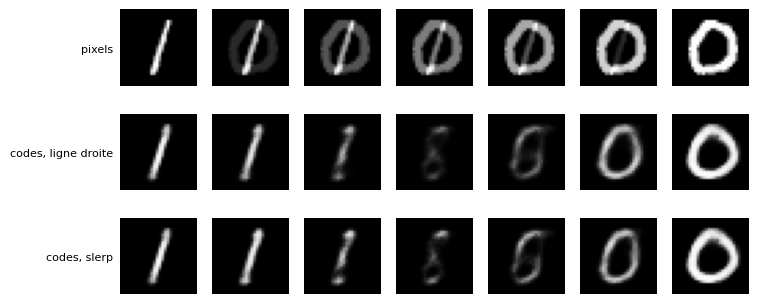

  pixels               distance à ce que l'AE sait refaire, étape par étape : 0.004 0.024 0.021 0.019 0.016 0.015 0.020
  codes, ligne droite  distance à ce que l'AE sait refaire, étape par étape : 0.001 0.001 0.001 0.001 0.001 0.001 0.000
  codes, slerp         distance à ce que l'AE sait refaire, étape par étape : 0.001 0.001 0.001 0.001 0.002 0.001 0.000


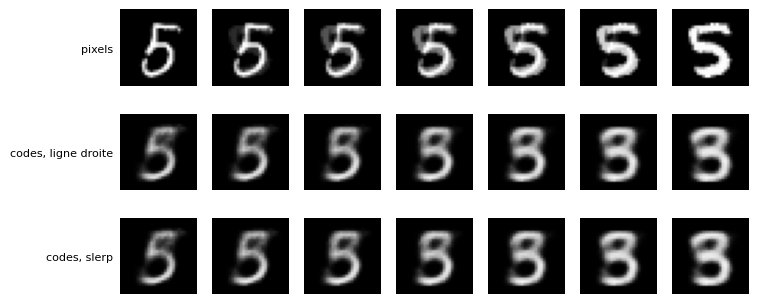

  pixels               distance à ce que l'AE sait refaire, étape par étape : 0.020 0.017 0.017 0.019 0.022 0.027 0.036
  codes, ligne droite  distance à ce que l'AE sait refaire, étape par étape : 0.001 0.001 0.001 0.001 0.001 0.000 0.000
  codes, slerp         distance à ce que l'AE sait refaire, étape par étape : 0.001 0.001 0.001 0.001 0.001 0.000 0.000


In [45]:
with checked("25.21"):
    def _pick_21(digit, k=0):
        return XM_TEST[np.flatnonzero(YM_TEST == digit)[k]]
    for (a_21, b_21) in [(_pick_21(1), _pick_21(0)), (_pick_21(5, 0), _pick_21(5, 3))]:
        rows_21 = {"pixels": blend_pixels_21(a_21, b_21, 7), "codes, ligne droite": blend_codes_21(AE_DEEP, a_21, b_21, 7),
                   "codes, slerp": blend_codes_21(AE_DEEP, a_21, b_21, 7, method="slerp")}
        show_rows(list(rows_21.values()), list(rows_21.keys()), size=1.1)
        for name_21, images_21 in rows_21.items():
            print(f"  {name_21:20s} distance à ce que l'AE sait refaire, étape par étape : "
                  + " ".join(f"{v:.3f}" for v in off_manifold_21(AE_DEEP, images_21)))

### Ex 25.22 — Taille du goulot et profondeur : la courbe d'erreur de reconstruction 🔬 ★★★ ⏱️ 40 min
**Objectif :** tracer l'erreur de reconstruction selon la taille du goulot, pour un autoencodeur dense et un profond.  
**Prérequis :** Ex 25.16 · fiche §25.4 · **Fil rouge :** MNIST · **Parcours :** C

La fiche résume la leçon du §25.4 : il faut **assez de latents** et **assez de capacité**. Tu mesures les deux ensemble : l'erreur de test de l'autoencodeur dense (`make_dense_ae`) et du profond (`make_deep_ae`) pour des goulots de 2, 5, 10, 20 et 50 latents.

**Contrat** : `bottleneck_sweep_22(sizes, makers, epochs, seed=2522, x=None)` : pour chaque nom et chaque fonction du dictionnaire `makers`, et chaque taille de `sizes`, `torch.manual_seed(seed)`, puis `model = maker(size)`, `train_ae(model, x, epochs, seed=seed)` (avec `x = X_MNIST` si `x` vaut `None`), puis la MSE moyenne de reconstruction sur `XM_TEST` ; elle rend le dictionnaire `{(nom, taille): MSE}`.

La vérification compare ta fonction à un entraînement fait à la main sur un cas d'essai. La cellule suivante lance les dix entraînements (une quarantaine de secondes en mode rapide, 4 epochs) et trace les deux courbes.

Dans tes notes : comment l'erreur baisse-t-elle quand le goulot grandit (régulièrement, ou de moins en moins) ? Pour quelles tailles la profondeur aide-t-elle le plus ? Avec 4 epochs, quel modèle est désavantagé, et comment le vérifierais-tu ?

In [46]:
def bottleneck_sweep_22(sizes, makers, epochs, seed=2522, x=None):
    """For each name, maker of the dict `makers` and each size of `sizes`: torch.manual_seed(seed), model =
    maker(size), train_ae(model, x, epochs, seed=seed) (x = X_MNIST if None), then the mean MSE of reconstruction
    on XM_TEST. Returns the dict {(name, size): that MSE}."""
    x = X_MNIST if x is None else x
    results = {}
    for name, maker in makers.items():
        for size in sizes:
            torch.manual_seed(seed)
            model = maker(size)
            train_ae(model, x, epochs, seed=seed)
            results[(name, size)] = float(mse_per_image(reconstruct(model, XM_TEST), XM_TEST).mean())
    return results


with checked("25.22"):
    tiny_22 = bottleneck_sweep_22([3], {"dense": make_dense_ae}, epochs=1, seed=7, x=X_MNIST[:512])
    if returned("25.22", "bottleneck_sweep_22", tiny_22):
        torch.manual_seed(7)
        model_22 = make_dense_ae(3)
        train_ae(model_22, X_MNIST[:512], 1, seed=7)
        want_22 = float(mse_per_image(reconstruct(model_22, XM_TEST), XM_TEST).mean())
        verdict("25.22", isinstance(tiny_22, dict) and set(tiny_22) == {("dense", 3)}
                and abs(tiny_22[("dense", 3)] - want_22) < 1e-5,
                f"bottleneck_sweep_22 sur un cas d'essai : {{('dense', 3): {want_22:.4f}}}.",
                f"attendu {{('dense', 3): {want_22:.4f}}}, reçu {tiny_22!r:.200} (torch.manual_seed(seed) juste avant "
                "maker(size), puis train_ae(..., seed=seed)).")

✅ Ex 25.22 : bottleneck_sweep_22 sur un cas d'essai : {('dense', 3): 0.2370}.


10 entraînements en 35 s


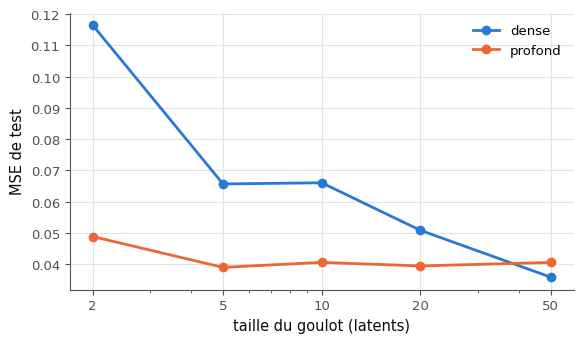

  2 latents · dense 0.1165 · profond 0.0488
  5 latents · dense 0.0656 · profond 0.0389
 10 latents · dense 0.0660 · profond 0.0406
 20 latents · dense 0.0508 · profond 0.0394
 50 latents · dense 0.0358 · profond 0.0405


In [47]:
with checked("25.22"):
    SIZES_22 = (2, 5, 10, 20, 50)
    EPOCHS_22 = 4 if FAST_MODE else 15
    start_22 = time.perf_counter()
    sweep_22 = bottleneck_sweep_22(SIZES_22, {"dense": make_dense_ae, "profond": make_deep_ae}, EPOCHS_22)
    print(f"{len(sweep_22)} entraînements en {time.perf_counter() - start_22:.0f} s")
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    for name_22 in ("dense", "profond"):
        ax.plot(SIZES_22, [sweep_22[(name_22, s)] for s in SIZES_22], "o-", label=name_22)
    ax.set_xscale("log")
    ax.set_xticks(SIZES_22, [str(s) for s in SIZES_22])
    ax.set_xlabel("taille du goulot (latents)")
    ax.set_ylabel("MSE de test")
    ax.legend()
    plt.show()
    for s_22 in SIZES_22:
        print(f"{s_22:3d} latents · dense {sweep_22[('dense', s_22)]:.4f} · profond {sweep_22[('profond', s_22)]:.4f}")

### Ex 25.23 — L'autoencodeur linéaire face à l'ACP de scikit-learn 🔬 ★★★ ⏱️ 40 min
**Objectif :** vérifier par l'expérience qu'un autoencodeur linéaire retrouve le sous-espace de l'ACP, mais pas ses axes.  
**Prérequis :** ∂ 25.8 · ch. 12 (ACP) · fiche §25.6 · **Fil rouge :** MNIST · **Parcours :** M, C

Le ∂ 25.8 l'a démontré dans le plan : un autoencodeur linéaire entraîné à l'erreur quadratique retrouve le **sous-espace** de l'ACP, pas ses axes. Tu le vérifies sur MNIST, avec 16 latents. Deux sous-espaces se comparent par leurs **angles principaux** : tous nuls quand les sous-espaces sont les mêmes, quelle que soit la base qui les décrit (`scipy.linalg.subspace_angles`).

**Contrat**
- `fit_linear_ae_23(xc, k, epochs=40, lr=3e-3, batch_size=256, seed=2523)` : un autoencodeur **linéaire** sur les images centrées `xc` `(N, 784)` : encodeur `nn.Linear(784, k, bias=False)` et décodeur `nn.Linear(k, 784, bias=False)`, sans activation, créés dans cet ordre juste après `torch.manual_seed(seed)`, entraînés par `train_ae` avec l'erreur quadratique (`loss="mse"`) et les mêmes `epochs`, `lr`, `batch_size` et `seed` ; elle rend le poids du décodeur en tableau NumPy `(784, k)` : ses $k$ colonnes engendrent le sous-espace appris ;
- `subspace_angles_deg_23(A, B)` rend les angles principaux, en degrés, entre le sous-espace des colonnes de `A` et celui de `B`, du plus grand au plus petit.

La vérification essaie tes angles sur deux plans de l'espace, puis ta fonction d'entraînement sur un petit cas. La cellule suivante centre 10 000 images, calcule l'ACP à 16 composantes (`svd_solver="full"`), entraîne ton autoencodeur (quelques secondes), et compare : les erreurs de reconstruction, les angles entre les sous-espaces, les colonnes du décodeur face aux axes de l'ACP.

Dans tes notes : les deux sous-espaces sont-ils les mêmes ? Pourquoi les plus grands angles sont-ils ceux des dernières directions (pense aux valeurs propres voisines) ? Les colonnes du décodeur sont-elles les axes de l'ACP, et sont-elles orthogonales ? Pourquoi un test « mêmes axes » aurait-il échoué ?

In [48]:
def fit_linear_ae_23(xc, k, epochs=40, lr=3e-3, batch_size=256, seed=2523):
    """A LINEAR autoencoder on the centred images xc (N, 784): encoder nn.Linear(784, k, bias=False), decoder
    nn.Linear(k, 784, bias=False), no activation, both created just after torch.manual_seed(seed); trained with
    Adam(lr) on the mean squared error, mini-batches in an order drawn by ONE torch.Generator().manual_seed(seed).
    Returns the decoder's weight as a NumPy array (784, k): its k columns span the learned subspace."""
    torch.manual_seed(seed)
    model = AutoEncoder(nn.Linear(784, k, bias=False), nn.Linear(k, 784, bias=False))
    train_ae(model, xc, epochs, lr=lr, batch_size=batch_size, seed=seed, loss="mse")
    return model.decoder.weight.detach().cpu().numpy().astype(np.float64)


def subspace_angles_deg_23(A, B):
    """The principal angles, in degrees, between the subspace spanned by the columns of A and that of B (both
    (p, k)), from the largest to the smallest: scipy.linalg.subspace_angles, converted."""
    return np.degrees(subspace_angles(np.asarray(A, dtype=np.float64), np.asarray(B, dtype=np.float64)))


with checked("25.23"):
    plane_a_23 = np.array([[1.0, 0.0], [0.0, 1.0], [0.0, 0.0]])                       # the plane z = 0
    tilt_23 = np.radians(30)
    plane_b_23 = np.array([[1.0, 0.0], [0.0, np.cos(tilt_23)], [0.0, np.sin(tilt_23)]])  # the same, tilted by 30°
    ang_23 = subspace_angles_deg_23(plane_a_23, plane_b_23)
    if returned("25.23", "subspace_angles_deg_23", ang_23):
        same("25.23", "subspace_angles_deg_23(plan z = 0, le même incliné de 30°)", ang_23, [30.0, 0.0], atol=1e-9)
        same("25.23", "deux bases différentes du même plan", subspace_angles_deg_23(plane_a_23, plane_a_23 @ [[2.0, 1.0], [1.0, 3.0]]),
             [0.0, 0.0], atol=1e-6)
    xc_23 = X_MNIST[:2000] - X_MNIST[:2000].mean(axis=0)
    W_23 = fit_linear_ae_23(xc_23, 4, epochs=2)
    if returned("25.23", "fit_linear_ae_23", W_23):
        torch.manual_seed(2523)
        enc_23, dec_23 = nn.Linear(784, 4, bias=False), nn.Linear(4, 784, bias=False)
        train_ae(AutoEncoder(enc_23, dec_23), xc_23, 2, lr=3e-3, batch_size=256, seed=2523, loss="mse")
        same("25.23", "fit_linear_ae_23(2 000 images centrées, k=4, epochs=2) : la matrice du décodeur (784, 4)",
             W_23, dec_23.weight.detach().cpu().numpy(), rtol=1e-4, atol=1e-6)

✅ Ex 25.23 : subspace_angles_deg_23(plan z = 0, le même incliné de 30°) : [30.0, 0.0], comme attendu.
✅ Ex 25.23 : deux bases différentes du même plan : [0.0, 0.0], comme attendu.
✅ Ex 25.23 : fit_linear_ae_23(2 000 images centrées, k=4, epochs=2) : la matrice du décodeur (784, 4) : un tableau (784, 4), comme attendu.


MSE de reconstruction · ACP 0.02725 · autoencodeur linéaire 0.02727
angles entre les deux sous-espaces (degrés) : max 6.4 · moyenne 1.6
|cos| entre chaque colonne du décodeur et l'axe de l'ACP de même rang : [0.02 0.44 0.2  0.   0.05 0.03 0.38 0.27 0.6  0.32 0.45 0.07 0.34 0.16
 0.11 0.16]
colonnes du décodeur orthogonales ? plus grand |cos| entre deux d'entre elles : 0.10


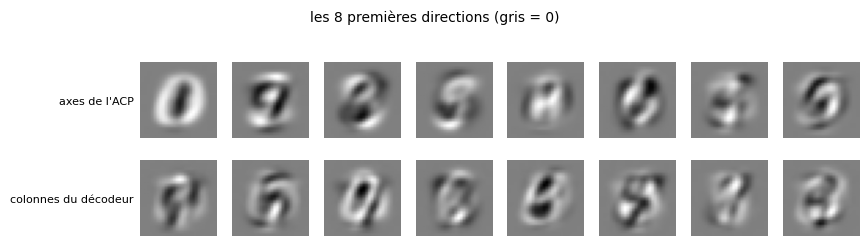

In [49]:
with checked("25.23"):
    K_23 = 16
    x_23 = X_MNIST[:N_FIXED].astype(np.float64)
    xc_23 = x_23 - x_23.mean(axis=0)                          # centred with the mean of the training images
    pca_23 = PCA(n_components=K_23, svd_solver="full").fit(xc_23)
    P_23 = pca_23.components_.T                               # (784, K): the first K principal axes
    W_23 = fit_linear_ae_23(xc_23.astype(np.float32), K_23)
    def _rec_mse_23(basis):
        Q, _ = np.linalg.qr(basis)                            # an orthonormal basis of the same subspace
        return float(((xc_23 - xc_23 @ Q @ Q.T) ** 2).mean())
    angles_23 = subspace_angles_deg_23(W_23, P_23)
    print(f"MSE de reconstruction · ACP {_rec_mse_23(P_23):.5f} · autoencodeur linéaire {_rec_mse_23(W_23):.5f}")
    print(f"angles entre les deux sous-espaces (degrés) : max {angles_23.max():.1f} · moyenne {angles_23.mean():.1f}")
    unit_23 = W_23 / np.linalg.norm(W_23, axis=0)
    print("|cos| entre chaque colonne du décodeur et l'axe de l'ACP de même rang :",
          np.round(np.abs((unit_23 * P_23).sum(axis=0)), 2))
    gram_23 = unit_23.T @ unit_23
    print(f"colonnes du décodeur orthogonales ? plus grand |cos| entre deux d'entre elles : "
          f"{np.abs(gram_23 - np.eye(K_23)).max():.2f}")
    show_rows([P_23.T[:8] / np.abs(P_23.T[:8]).max(axis=1, keepdims=True) / 2 + 0.5,
               unit_23.T[:8] / np.abs(unit_23.T[:8]).max(axis=1, keepdims=True) / 2 + 0.5],
              ["axes de l'ACP", "colonnes du décodeur"], "les 8 premières directions (gris = 0)", size=1.1)

## Partie B · Autoencodeurs convolutifs et débruiteurs

Tu construis l'autoencodeur convolutif du livre (25.24), tu répares un débruiteur qui apprenait le bruit (25.25), tu débruites Fashion-MNIST (25.26), puis tu remplaces pooling et sur-échantillonnage par des convolutions à pas (25.27). La cellule suivante fixe le bruit des débruiteurs de vêtements ($\sigma = 0{,}3$), leurs images d'entraînement (`N_DENOISE` : 5 000 en mode rapide) et 1 000 vêtements de validation avec leur version bruitée (un bruit fixé), et donne `layout`, qui écrit brièvement les couches d'un `nn.Sequential` (les vérifications comparent ces listes).

In [50]:
SIGMA_B = 0.3                                   # the noise of the Fashion-MNIST denoisers (25.26, 25.27, 25.39)
N_DENOISE = 5_000 if FAST_MODE else 60_000      # their training images
VAL_CLEAN_B = XF_TEST[:1000]                     # 1 000 validation clothes, and their noisy version (a fixed noise)
VAL_NOISY_B = np.clip(VAL_CLEAN_B + SIGMA_B * np.random.default_rng(2526).standard_normal(VAL_CLEAN_B.shape),
                      0, 1).astype(np.float32)


def layout(seq):
    """The layers of a nn.Sequential, written briefly: what the checks compare."""
    out = []
    for m in seq:
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            extra = f", op={m.output_padding[0]}" if isinstance(m, nn.ConvTranspose2d) else ""
            out.append(f"{type(m).__name__}({m.in_channels}, {m.out_channels}, k={m.kernel_size[0]}, "
                       f"s={m.stride[0]}, p={m.padding[0]}{extra})")
        elif isinstance(m, nn.Linear):
            out.append(f"Linear({m.in_features}, {m.out_features})")
        elif isinstance(m, nn.Upsample):
            out.append(f"Upsample({m.scale_factor:g})")
        elif isinstance(m, nn.MaxPool2d):
            out.append(f"MaxPool2d({m.kernel_size})")
        elif isinstance(m, nn.Unflatten):
            out.append(f"Unflatten{tuple(m.unflattened_size)}")
        else:
            out.append(type(m).__name__)
    return out

### Ex 25.24 — Autoencodeur convolutif à 147 latents 📦 ★★ ⏱️ 30 min
**Objectif :** écrire l'autoencodeur convolutif du livre et comparer son code de 147 valeurs à celui de l'autoencodeur dense.  
**Prérequis :** ✏️ 25.3 · ch. 21 (convolutions, pooling) · fiche §25.7, §25.7.1, §25.7.2 · **Fil rouge :** MNIST · **Parcours :** R, C

Le ✏️ 25.3 a suivi les formes de l'autoencodeur convolutif du livre ; tu l'écris. Pour garder la convention du notebook (des lignes de 784 pixels), l'encodeur commence par `nn.Unflatten(1, (1, 28, 28))` et le décodeur finit par `nn.Flatten()`.

**Contrat** : `make_conv_ae_24()` rend un `AutoEncoder` dont l'encodeur est `nn.Unflatten(1, (1, 28, 28))`, `Conv2d(1, 16, 3, padding=1)`, ReLU, `MaxPool2d(2)`, `Conv2d(16, 8, 3, padding=1)`, ReLU, `MaxPool2d(2)`, `Conv2d(8, 3, 3, padding=1)`, ReLU, et le décodeur `nn.Upsample(scale_factor=2)`, `Conv2d(3, 16, 3, padding=1)`, ReLU, `nn.Upsample(scale_factor=2)`, `Conv2d(16, 1, 3, padding=1)`, sigmoïde, `nn.Flatten()`.

La vérification compare tes couches au contrat et regarde les formes du code et de la sortie. La cellule suivante l'entraîne (3 epochs en mode rapide, une quinzaine de secondes), compare son erreur à celle de `AE_DEEP`, et décode une ligne droite entre les codes d'un 1 et d'un 0.

Dans tes notes : combien de paramètres a ce modèle, face au 1,1 million de `AE_DEEP` ? Son code est-il plus petit ou plus grand ? Que donne le mélange des codes : une transformation, ou un fondu (fiche §25.7.1) ?

In [51]:
def make_conv_ae_24():
    """The book's convolutional autoencoder, for rows of 784 pixels:
    encoder: nn.Unflatten(1, (1, 28, 28)), Conv2d(1, 16, 3, padding=1), ReLU, MaxPool2d(2),
             Conv2d(16, 8, 3, padding=1), ReLU, MaxPool2d(2), Conv2d(8, 3, 3, padding=1), ReLU  -> a code (N, 3, 7, 7)
    decoder: nn.Upsample(scale_factor=2), Conv2d(3, 16, 3, padding=1), ReLU, nn.Upsample(scale_factor=2),
             Conv2d(16, 1, 3, padding=1), Sigmoid, nn.Flatten()                              -> rows of 784 pixels
    Returns an AutoEncoder whose encoder and decoder are these two nn.Sequential."""
    encoder = nn.Sequential(nn.Unflatten(1, (1, 28, 28)),
                            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 16 x 14 x 14
                            nn.Conv2d(16, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 8 x 7 x 7
                            nn.Conv2d(8, 3, 3, padding=1), nn.ReLU())                       # 3 x 7 x 7: the code
    decoder = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(),   # 16 x 14 x 14
                            nn.Upsample(scale_factor=2), nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid(),  # 1 x 28 x 28
                            nn.Flatten())
    return AutoEncoder(encoder, decoder)


with checked("25.24"):
    torch.manual_seed(0)
    model_24 = make_conv_ae_24()
    if returned("25.24", "make_conv_ae_24", model_24):
        want_enc_24 = ["Unflatten(1, 28, 28)", "Conv2d(1, 16, k=3, s=1, p=1)", "ReLU", "MaxPool2d(2)",
                       "Conv2d(16, 8, k=3, s=1, p=1)", "ReLU", "MaxPool2d(2)", "Conv2d(8, 3, k=3, s=1, p=1)", "ReLU"]
        want_dec_24 = ["Upsample(2)", "Conv2d(3, 16, k=3, s=1, p=1)", "ReLU", "Upsample(2)",
                       "Conv2d(16, 1, k=3, s=1, p=1)", "Sigmoid", "Flatten"]
        verdict("25.24", layout(model_24.encoder) == want_enc_24, "l'encodeur suit le contrat.",
                f"encodeur attendu {want_enc_24}, reçu {layout(model_24.encoder)}.")
        verdict("25.24", layout(model_24.decoder) == want_dec_24, "le décodeur suit le contrat.",
                f"décodeur attendu {want_dec_24}, reçu {layout(model_24.decoder)}.")
        code_24 = encode(model_24, X_MNIST[:5])
        verdict("25.24", code_24.shape == (5, 3, 7, 7) and reconstruct(model_24, X_MNIST[:5]).shape == (5, 784),
                f"un code {shape_text(code_24)} pour 5 images, une sortie (5, 784).",
                f"attendu un code (5, 3, 7, 7) et une sortie (5, 784), reçu {shape_text(code_24)}.")

✅ Ex 25.24 : l'encodeur suit le contrat.
✅ Ex 25.24 : le décodeur suit le contrat.
✅ Ex 25.24 : un code [[[[0.00000000e+00 6.25007004e-02 3.94774117e-02 1.49058327e-02
    4.54942100e-02 4.00802307e-02 0.00000000e+00]
   [5.10101728e-02 9.35804993e-02 1.08053505e-01 9.98555571e-02
    8.79108906e-02 5.76549359e-02 0.00000000e+00]
   [4.69158627e-02 1.23760834e-01 9.45369005e-02 4.84037884e-02
    1.11284912e-01 7.94525445e-02 0.00000000e+00]
   [5.15373014e-02 9.29249525e-02 7.32011199e-02 1.41440287e-01
    8.79898816e-02 5.55764623e-02 0.00000000e+00]
   [5.78225069e-02 1.28716543e-01 8.21420103e-02 6.44978881e-02
    7.28660822e-02 5.74556254e-02 0.00000000e+00]
   [4.96522598e-02 7.62031972e-02 6.75915033e-02 4.53551859e-03
    8.06961805e-02 3.31257470e-02 0.00000000e+00]
   [3.08577679e-02 1.35004073e-02 0.00000000e+00 0.00000000e+00
    0.00000000e+00 0.00000000e+00 0.00000000e+00]]

  [[7.69848749e-03 0.00000000e+00 0.00000000e+00 0.00000000e+00
    0.00000000e+00 0.00000000e+0

convolutif : 2,132 paramètres, code de 147 valeurs · MSE de test 0.1005 (11 s) · AE_DEEP (20 latents) : 0.0271


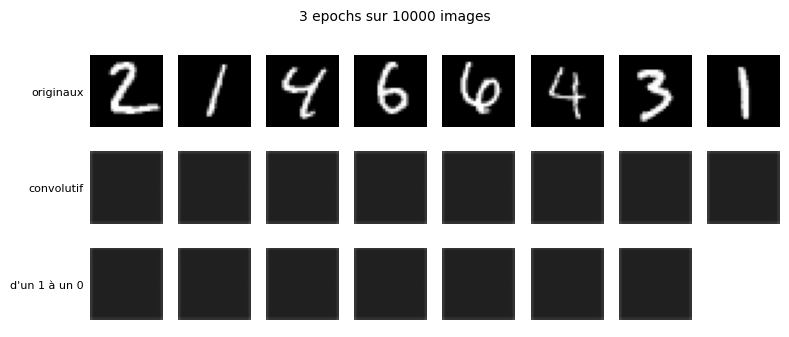

In [52]:
with checked("25.24"):
    EPOCHS_24 = 3 if FAST_MODE else 10
    torch.manual_seed(2524)
    conv_24 = make_conv_ae_24()
    history_24 = train_ae(conv_24, X_MNIST, EPOCHS_24, seed=2524, x_val=XM_TEST)
    print(f"convolutif : {n_params(conv_24):,d} paramètres, code de {3 * 7 * 7} valeurs · MSE de test "
          f"{history_24['val_mse'][-1]:.4f} ({sum(history_24['seconds']):.0f} s) · AE_DEEP (20 latents) : "
          f"{mse_per_image(reconstruct(AE_DEEP, XM_TEST), XM_TEST).mean():.4f}")
    x0_24, x1_24 = XM_TEST[np.flatnonzero(YM_TEST == 1)[0]], XM_TEST[np.flatnonzero(YM_TEST == 0)[0]]
    c0_24, c1_24 = encode(conv_24, np.stack([x0_24, x1_24])).reshape(2, -1)        # codes flattened to 147 values
    path_24 = np.stack([(1 - t) * c0_24 + t * c1_24 for t in np.linspace(0, 1, 7)]).reshape(7, 3, 7, 7)
    show_rows([XM_TEST[:8], reconstruct(conv_24, XM_TEST[:8]), decode(conv_24, path_24.astype(np.float32))],
              ["originaux", "convolutif", "d'un 1 à un 0"], f"{EPOCHS_24} epochs sur {len(X_MNIST)} images")

### Ex 25.25 — Le débruiteur qui apprenait le bruit 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver les trois erreurs d'une boucle d'entraînement de débruiteur, et la corriger.  
**Prérequis :** Ex 25.24 · fiche §25.8 · **Fil rouge :** MNIST · **Parcours :** C

Un collègue a écrit la boucle d'entraînement d'un débruiteur (la cellule suivante), et ses images « débruitées » restent pleines de neige. Trois lignes sont fausses. Les diagnostics de la cellule donnée l'essaient avec un faux modèle qui note ce qu'il reçoit (pas d'entraînement réel : ils sont instantanés), dans cet ordre : 1) la cible est-elle l'image propre ? 2) une même image reçoit-elle un bruit neuf à chaque epoch ? 3) les entrées bruitées restent-elles dans $[0, 1]$ ?

1. Écris dans `faulty_25` les lettres des **lignes fautives** (une chaîne comme `"AB"`).
2. Écris `train_denoiser_fixed_25`, la version corrigée : mêmes arguments ; un seul `torch.Generator` créé depuis `seed`, un `torch.randperm(N, generator=g)` au début de chaque epoch ; pour chaque mini-batch, un bruit **neuf** `sigma * torch.randn(batch.shape, generator=g)`, des entrées bruitées **écrêtées** dans $[0, 1]$ (`torch.clamp`), et la loss `loss_fn(model(entrées bruitées), batch propre)` ; la fonction rend le modèle.

La vérification lance les trois diagnostics sur ta version ; s'ils passent, elle entraîne un petit débruiteur dense avec ta fonction et montre le résultat.

Dans tes notes : pour chaque erreur, qu'apprendrait le réseau, et comment le verrais-tu sur les images ou sur les courbes ? Laquelle est la plus grave ?

In [53]:
# The code to debug (do not change this cell: copy the function into the next one to fix it)
def train_denoiser_25(model, x, epochs, sigma=0.5, lr=1e-3, batch_size=128, seed=0, loss_fn=F.binary_cross_entropy):
    """Train `model` to remove a gaussian noise of standard deviation sigma from the images x (N, 784) in [0, 1]."""
    x = to_tensor(x)                                                   # (A)
    g = torch.Generator().manual_seed(seed)                            # (B)
    noise = sigma * torch.randn(x.shape, generator=g)                  # (C)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)            # (D)
    model.train()
    for epoch in range(epochs):
        order = torch.randperm(len(x), generator=g)                    # (E)
        for i in range(0, len(x), batch_size):
            idx = order[i:i + batch_size]
            inputs = x[idx] + noise[idx]                               # (F)
            loss = loss_fn(model(inputs.to(DEVICE)), inputs.to(DEVICE))   # (G)
            optimizer.zero_grad()
            loss.backward()                                            # (H)
            optimizer.step()
    return model


class SpyModel_25(nn.Module):
    """A fake model for the checks: it remembers the inputs it receives, and returns a constant grey image."""

    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(1))
        self.inputs = []

    def forward(self, x):
        self.inputs.append(x.detach().cpu().clone())
        return torch.sigmoid(self.w).expand_as(x)


def spy_run_25(train_fn, epochs=2, sigma=1.0):
    """Run train_fn on 8 distinct images with a SpyModel_25 and a loss that remembers its targets:
    returns (the images, the inputs seen, the targets seen), one tensor per mini-batch."""
    x = np.random.default_rng(25).uniform(0.2, 0.8, size=(8, 784)).astype(np.float32)
    targets = []

    def spy_loss(output, target):
        targets.append(target.detach().cpu().clone())
        return F.binary_cross_entropy(output, target.clamp(0, 1))

    spy = SpyModel_25()
    train_fn(spy, x, epochs, sigma=sigma, batch_size=4, seed=3, loss_fn=spy_loss)
    return torch.from_numpy(x), spy.inputs, targets


def diagnose_25(train_fn):
    """The three diagnostics of 25.25, in order: the target, the noise of each epoch, the clipping.
    Prints ✅ or ❌ for each one, stops at the first ❌ (⏳ for the next ones)."""
    x, inputs, targets = spy_run_25(train_fn)
    points = [
        ("la cible est l'image propre",
         all(any(torch.equal(row, clean) for clean in x) for batch in targets for row in batch),
         "la cible d'un mini-batch doit être l'image propre, pas l'entrée bruitée."),
        ("un bruit neuf à chaque epoch",
         not torch.equal(torch.cat(inputs[:len(inputs) // 2]).sort(dim=0).values,
                         torch.cat(inputs[len(inputs) // 2:]).sort(dim=0).values),
         "une même image reçoit le même bruit à chaque epoch : le réseau peut apprendre le bruit par cœur."),
        ("des entrées dans [0, 1]",
         all(float(b.min()) >= 0 and float(b.max()) <= 1 for b in inputs),
         "les entrées bruitées sortent de [0, 1] : le réseau voit des pixels qui n'existent pas (écrête-les)."),
    ]
    for k, (name, ok, why) in enumerate(points, start=1):
        if ok:
            print(f"✅ Ex 25.25 : point {k}, {name}.")
        else:
            print(f"❌ Ex 25.25 : point {k} : {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex 25.25 : point {later} : corrige d'abord le point {k}.")
            return False
    return True


print("Le code fautif, essayé par les diagnostics :")
diagnose_25(train_denoiser_25)

Le code fautif, essayé par les diagnostics :
❌ Ex 25.25 : point 1 : la cible d'un mini-batch doit être l'image propre, pas l'entrée bruitée.
⏳ Ex 25.25 : point 2 : corrige d'abord le point 1.
⏳ Ex 25.25 : point 3 : corrige d'abord le point 1.


False

❓ Ex 25.25 : aucune réponse enregistrée pour cet exercice. Vérifie l'ID, puis fais un `git pull` (le fichier src/wb/answers.json est peut-être plus récent sur GitHub).
✅ Ex 25.25 : point 1, la cible est l'image propre.
✅ Ex 25.25 : point 2, un bruit neuf à chaque epoch.
✅ Ex 25.25 : point 3, des entrées dans [0, 1].


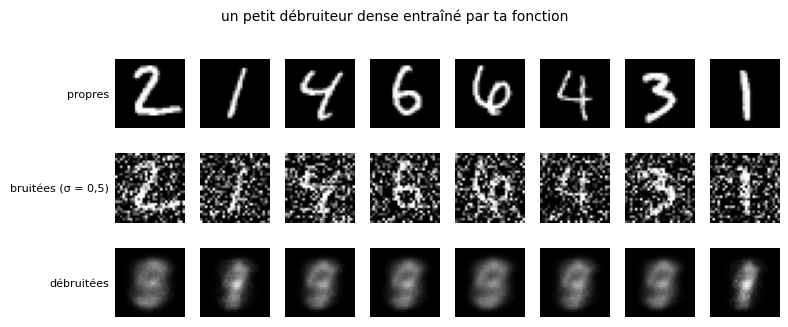

In [54]:
faulty_25 = "CFG"


def train_denoiser_fixed_25(model, x, epochs, sigma=0.5, lr=1e-3, batch_size=128, seed=0,
                            loss_fn=F.binary_cross_entropy):
    """The fixed version of train_denoiser_25: same arguments, same mini-batches (one torch.Generator from `seed`,
    a torch.randperm(N, generator=g) at the start of each epoch). For each mini-batch: a new noise
    sigma * torch.randn(batch.shape, generator=g), noisy inputs clipped to [0, 1] (torch.clamp), and the loss
    loss_fn(model(noisy inputs), clean batch). Returns the model."""
    x = to_tensor(x)
    g = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(epochs):
        order = torch.randperm(len(x), generator=g)
        for i in range(0, len(x), batch_size):
            clean = x[order[i:i + batch_size]]
            inputs = torch.clamp(clean + sigma * torch.randn(clean.shape, generator=g), 0, 1)  # a new noise, clipped
            loss = loss_fn(model(inputs.to(DEVICE)), clean.to(DEVICE))                        # the target is clean
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model


wb.check("25.25", faulty_25)
with checked("25.25"):
    if written(lambda: train_denoiser_fixed_25(SpyModel_25(), np.zeros((1, 784), np.float32), 0)):
        if diagnose_25(train_denoiser_fixed_25):
            torch.manual_seed(2525)
            small_25 = make_deep_ae(32, hidden=(256,))
            train_denoiser_fixed_25(small_25.to(DEVICE), X_MNIST[:5000], 3 if FAST_MODE else 10, sigma=0.5, seed=2525)
            noisy_25 = np.clip(XM_TEST[:8] + 0.5 * np.random.default_rng(25).standard_normal((8, 784)), 0, 1).astype(np.float32)
            show_rows([XM_TEST[:8], noisy_25, reconstruct(small_25, noisy_25)], ["propres", "bruitées (σ = 0,5)", "débruitées"],
                      "un petit débruiteur dense entraîné par ta fonction")
    else:
        print("⏳ Ex 25.25 : les diagnostics attendent ta fonction corrigée.")

In [55]:
wb.record("25.25", "CFG", mistakes={"il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "FG",
                     "il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "CG",
                     "il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "CF",
                     "une ligne de trop : la ligne (A) est correcte ; relis ce qu'elle fait": "ACFG",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "BCFG",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "CDFG",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "CEFG",
                     "une ligne de trop : la ligne (H) est correcte ; relis ce qu'elle fait": "CFGH",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "AFG",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "BFG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "DFG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "EFG",
                     "la ligne (H) est correcte, et il manque une ligne fautive : un des diagnostics compare le bruit d'une même image d'une epoch à l'autre": "FGH",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "ACG",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "BCG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "CDG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "CEG",
                     "la ligne (H) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées": "CGH",
                     "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "ACF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "BCF",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "CDF",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "CEF",
                     "la ligne (H) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss": "CFH"})

WB_ANSWER {"hash": "5403a1b971b9486c7baf12cd10b2f2983e8e2596b13108c15b9d9847046dffae", "id": "25.25", "kind": "str", "mistakes": {"0020cf08188b7fd71aa0ee9333525353e5c661f1f6564037ece1368b28a1381f": "la ligne (E) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées", "0e99a841e2221c386d2332555d429a1df1eee3feb798959d42d7fa14892b308b": "la ligne (A) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss", "0ed930e1f956e94e934f75bb62adb0c29df9181225b4b7a03a9f94f790316cd4": "la ligne (H) est correcte, et il manque une ligne fautive : un des diagnostics regarde les valeurs des entrées bruitées", "0f0e3a3867e15a950f11ec68b5cf7077171bdccc9ba2e730df7b71e1704942bf": "la ligne (H) est correcte, et il manque une ligne fautive : un des diagnostics regarde la cible de la loss", "11e80b2dc2ac441fd815724ac5893b05c49750c1ad6e0e5f67f4a027cb7e67ac": "une ligne de trop : la ligne (E) est correcte ; relis ce qu'ell

La cellule suivante donne la version de référence de la boucle corrigée, `train_denoiser`, et `psnr`, qui servent aux exercices suivants.

In [56]:
# The reference version of your fixed loop (25.25), with a history: the denoisers of 25.26, 25.27 and 25.39 use it
def train_denoiser(model, x, epochs, sigma=SIGMA_B, lr=1e-3, batch_size=128, seed=0, x_val=None, verbose=False):
    """Train the autoencoder `model` in place (on DEVICE) to turn noisy images back into the clean images x (N, 784):
    a new gaussian noise of standard deviation sigma for each mini-batch, noisy inputs clipped to [0, 1], the binary
    cross-entropy against the CLEAN batch, Adam(lr). x_val = (noisy, clean) adds "val_psnr" to the history."""
    model.to(DEVICE)
    x = to_tensor(x)
    g = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"loss": [], "val_psnr": [], "seconds": []}
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        model.train()
        total = 0.0
        order = torch.randperm(len(x), generator=g)
        for i in range(0, len(x), batch_size):
            clean = x[order[i:i + batch_size]]
            inputs = torch.clamp(clean + sigma * torch.randn(clean.shape, generator=g), 0, 1)
            loss = F.binary_cross_entropy(model(inputs.to(DEVICE)), clean.to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(clean)
        history["loss"].append(total / len(x))
        history["seconds"].append(time.perf_counter() - start)
        if x_val is not None:
            history["val_psnr"].append(psnr(x_val[1], reconstruct(model, x_val[0])))
        if verbose:
            print(f"epoch {epoch:2d} · loss {history['loss'][-1]:.4f}" +
                  (f" · val PSNR {history['val_psnr'][-1]:.2f} dB" if x_val is not None else ""))
    return history


def psnr(clean, images):
    """The mean PSNR (dB) of images against clean (pixels in [0, 1]): the mean over the images of 10 log10(1 / MSE)."""
    return float(np.mean(10 * np.log10(1.0 / np.maximum(mse_per_image(images, clean), 1e-12))))

### Ex 25.26 — Autoencodeur débruiteur (bruit gaussien, écrêtage) 📦 ★★ ⏱️ 30 min
**Objectif :** construire un débruiteur convolutif pour Fashion-MNIST et mesurer son gain en PSNR.  
**Prérequis :** Ex 25.24 · Ex 25.25 · fiche §25.8 · **Fil rouge :** Fashion-MNIST · **Parcours :** R, C

Le débruiteur du livre (celui de F. Chollet) garde 32 filtres à chaque étage : deux convolutions suivies d'un max pooling à l'encodage, et leur miroir au décodage. Tu l'entraînes sur des vêtements avec un bruit gaussien d'écart-type 0,3, et tu le mesures en **PSNR**.

**Contrat**
- `make_denoiser_26(channels=32)` rend un `AutoEncoder` ; avec $c$ = `channels`, l'encodeur est `nn.Unflatten(1, (1, 28, 28))`, `Conv2d(1, c, 3, padding=1)`, ReLU, `MaxPool2d(2)`, `Conv2d(c, c, 3, padding=1)`, ReLU, `MaxPool2d(2)`, et le décodeur `Conv2d(c, c, 3, padding=1)`, ReLU, `nn.Upsample(scale_factor=2)`, `Conv2d(c, c, 3, padding=1)`, ReLU, `nn.Upsample(scale_factor=2)`, `Conv2d(c, 1, 3, padding=1)`, sigmoïde, `nn.Flatten()` ;
- `psnr_26(clean, images)` rend le PSNR moyen en décibels de `images` face à `clean` (deux tableaux `(N, 784)`, pixels dans $[0, 1]$) : pour chaque image $10 \log_{10}(1/\text{MSE})$, puis la moyenne sur les images.

La vérification essaie ton architecture avec 8 filtres et ton PSNR sur deux images d'erreurs connues. La cellule suivante entraîne ton débruiteur avec `train_denoiser` (3 epochs sur 5 000 vêtements en mode rapide, une quinzaine de secondes), compare le PSNR des images bruitées et débruitées, et les montre.

Dans tes notes : combien de décibels gagne le débruiteur, et à quoi cela correspond-il en MSE (fiche : diviser la MSE par 10 ajoute 10 dB) ? Quels détails perd-il ? Pourquoi moyenne-t-on le PSNR image par image plutôt que de calculer celui de la MSE moyenne ?

In [57]:
def make_denoiser_26(channels=32):
    """A convolutional denoiser for rows of 784 pixels, with c = channels:
    encoder: nn.Unflatten(1, (1, 28, 28)), Conv2d(1, c, 3, padding=1), ReLU, MaxPool2d(2),
             Conv2d(c, c, 3, padding=1), ReLU, MaxPool2d(2)                         -> (N, c, 7, 7)
    decoder: Conv2d(c, c, 3, padding=1), ReLU, nn.Upsample(scale_factor=2), Conv2d(c, c, 3, padding=1), ReLU,
             nn.Upsample(scale_factor=2), Conv2d(c, 1, 3, padding=1), Sigmoid, nn.Flatten()
    Returns an AutoEncoder."""
    c = channels
    encoder = nn.Sequential(nn.Unflatten(1, (1, 28, 28)),
                            nn.Conv2d(1, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(c, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
    decoder = nn.Sequential(nn.Conv2d(c, c, 3, padding=1), nn.ReLU(), nn.Upsample(scale_factor=2),
                            nn.Conv2d(c, c, 3, padding=1), nn.ReLU(), nn.Upsample(scale_factor=2),
                            nn.Conv2d(c, 1, 3, padding=1), nn.Sigmoid(), nn.Flatten())
    return AutoEncoder(encoder, decoder)


def psnr_26(clean, images):
    """The mean PSNR in decibels of `images` against `clean` (both (N, 784), pixels in [0, 1]): for each image,
    10 log10(1 / MSE), then the mean over the images. A float."""
    mse = ((np.asarray(images, dtype=np.float64) - np.asarray(clean, dtype=np.float64)) ** 2).mean(axis=1)
    return float(np.mean(10 * np.log10(1.0 / mse)))


with checked("25.26"):
    torch.manual_seed(0)
    model_26 = make_denoiser_26(8)
    if returned("25.26", "make_denoiser_26", model_26):
        want_26 = (["Unflatten(1, 28, 28)", "Conv2d(1, 8, k=3, s=1, p=1)", "ReLU", "MaxPool2d(2)",
                    "Conv2d(8, 8, k=3, s=1, p=1)", "ReLU", "MaxPool2d(2)"],
                   ["Conv2d(8, 8, k=3, s=1, p=1)", "ReLU", "Upsample(2)", "Conv2d(8, 8, k=3, s=1, p=1)", "ReLU",
                    "Upsample(2)", "Conv2d(8, 1, k=3, s=1, p=1)", "Sigmoid", "Flatten"])
        verdict("25.26", (layout(model_26.encoder), layout(model_26.decoder)) == want_26,
                "make_denoiser_26(8) suit le contrat.",
                f"attendu {want_26}, reçu {(layout(model_26.encoder), layout(model_26.decoder))}.")
    toy_clean_26 = np.zeros((2, 784))
    toy_26 = toy_clean_26 + np.array([[0.1], [0.01]])          # MSE 0.01 then 0.0001: 20 dB then 40 dB
    value_26 = psnr_26(toy_clean_26, toy_26)
    if returned("25.26", "psnr_26", value_26):
        same("25.26", "psnr_26 de deux images d'erreurs 0,1 et 0,01 sur chaque pixel (20 et 40 dB)", [value_26], [30.0],
             rtol=1e-9)

✅ Ex 25.26 : make_denoiser_26(8) suit le contrat.
✅ Ex 25.26 : psnr_26 de deux images d'erreurs 0,1 et 0,01 sur chaque pixel (20 et 40 dB) : [30.0], comme attendu.


28,353 paramètres · 13 s · PSNR des images bruitées 12.79 dB · débruitées 17.02 dB
❌ Ex 25.26 : le débruiteur devrait gagner plus de 5 dB : vérifie ton architecture.


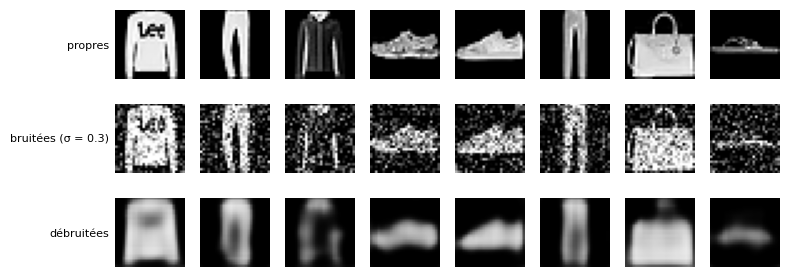

In [58]:
with checked("25.26"):
    EPOCHS_26 = 3 if FAST_MODE else 10
    torch.manual_seed(2526)
    denoiser_26 = make_denoiser_26(32)
    history_26 = train_denoiser(denoiser_26, X_FASHION[:N_DENOISE], EPOCHS_26, seed=2526)
    out_26 = reconstruct(denoiser_26, VAL_NOISY_B)
    print(f"{n_params(denoiser_26):,d} paramètres · {sum(history_26['seconds']):.0f} s · PSNR des images bruitées "
          f"{psnr_26(VAL_CLEAN_B, VAL_NOISY_B):.2f} dB · débruitées {psnr_26(VAL_CLEAN_B, out_26):.2f} dB")
    verdict("25.26", psnr_26(VAL_CLEAN_B, out_26) > psnr_26(VAL_CLEAN_B, VAL_NOISY_B) + 5,
            "le débruiteur gagne plus de 5 dB.", "le débruiteur devrait gagner plus de 5 dB : vérifie ton architecture.")
    show_rows([VAL_CLEAN_B[:8], VAL_NOISY_B[:8], out_26[:8]], ["propres", f"bruitées (σ = {SIGMA_B})", "débruitées"])

### Ex 25.27 — Sur-échantillonnage explicite ou convolutions à pas : temps et qualité 🔬 ★★★ ⏱️ 35 min
**Objectif :** comparer, à nombre de filtres égal, un débruiteur à pooling et sur-échantillonnage et un débruiteur à convolutions à pas.  
**Prérequis :** Ex 25.26 · ✏️ 25.4 · fiche §25.8 (et son encadré ⚠️) · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Le livre remplace le pooling et le sur-échantillonnage de son débruiteur par des convolutions à pas : un `Conv2d` de stride 2 réduit l'image, un `ConvTranspose2d` de stride 2 l'agrandit (le ✏️ 25.4 a calculé ses tailles). Tu mesures ce que cela change, au même nombre de filtres.

**Contrat**
- `make_strided_27(channels=32)` rend un `AutoEncoder` ; l'encodeur est `nn.Unflatten(1, (1, 28, 28))`, `Conv2d(1, c, 3, stride=2, padding=1)`, ReLU, `Conv2d(c, c, 3, stride=2, padding=1)`, ReLU ; le décodeur `ConvTranspose2d(c, c, 3, stride=2, padding=1, output_padding=1)`, ReLU, le même encore, ReLU, puis `Conv2d(c, 1, 3, padding=1)`, sigmoïde, `nn.Flatten()` ;
- `compare_27(makers, epochs, seed=2527)` : pour chaque nom et chaque fonction du dictionnaire `makers`, `torch.manual_seed(seed)`, `model = maker()`, `train_denoiser(model, X_FASHION[:N_DENOISE], epochs, seed=seed)` ; elle rend `{nom: {"params": ..., "sec_per_epoch": la médiane des durées, "psnr": le PSNR moyen sur VAL_NOISY_B face à VAL_CLEAN_B}}`.

La vérification compare tes couches au contrat, puis `compare_27` à un entraînement fait à la main. La cellule suivante entraîne les deux débruiteurs (2 epochs en mode rapide, une vingtaine de secondes ; 🚀 le mode complet est long sur un CPU).

Dans tes notes : lequel va le plus vite, et pourquoi (compte les positions où chaque convolution calcule) ? Lequel débruite le mieux à nombre d'epochs égal ? Une convolution transposée peut laisser un motif en damier : le vois-tu ici ?

In [59]:
def make_strided_27(channels=32):
    """The same denoiser without pooling nor upsampling, with c = channels:
    encoder: nn.Unflatten(1, (1, 28, 28)), Conv2d(1, c, 3, stride=2, padding=1), ReLU,
             Conv2d(c, c, 3, stride=2, padding=1), ReLU                                  -> (N, c, 7, 7)
    decoder: ConvTranspose2d(c, c, 3, stride=2, padding=1, output_padding=1), ReLU,
             ConvTranspose2d(c, c, 3, stride=2, padding=1, output_padding=1), ReLU,
             Conv2d(c, 1, 3, padding=1), Sigmoid, nn.Flatten()
    Returns an AutoEncoder."""
    c = channels
    encoder = nn.Sequential(nn.Unflatten(1, (1, 28, 28)),
                            nn.Conv2d(1, c, 3, stride=2, padding=1), nn.ReLU(),        # 28 -> 14
                            nn.Conv2d(c, c, 3, stride=2, padding=1), nn.ReLU())        # 14 -> 7
    decoder = nn.Sequential(nn.ConvTranspose2d(c, c, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 7 -> 14
                            nn.ConvTranspose2d(c, c, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 14 -> 28
                            nn.Conv2d(c, 1, 3, padding=1), nn.Sigmoid(), nn.Flatten())
    return AutoEncoder(encoder, decoder)


def compare_27(makers, epochs, seed=2527):
    """For each name, maker of the dict `makers`: torch.manual_seed(seed), model = maker(), train_denoiser(model,
    X_FASHION[:N_DENOISE], epochs, seed=seed). Returns {name: {"params": n_params(model), "sec_per_epoch": the
    median of history["seconds"], "psnr": the mean PSNR of model on VAL_NOISY_B against VAL_CLEAN_B}}."""
    results = {}
    for name, maker in makers.items():
        torch.manual_seed(seed)
        model = maker()
        history = train_denoiser(model, X_FASHION[:N_DENOISE], epochs, seed=seed)
        results[name] = {"params": n_params(model), "sec_per_epoch": float(np.median(history["seconds"])),
                         "psnr": psnr(VAL_CLEAN_B, reconstruct(model, VAL_NOISY_B))}
    return results


with checked("25.27"):
    torch.manual_seed(0)
    model_27 = make_strided_27(8)
    if returned("25.27", "make_strided_27", model_27):
        want_27 = (["Unflatten(1, 28, 28)", "Conv2d(1, 8, k=3, s=2, p=1)", "ReLU", "Conv2d(8, 8, k=3, s=2, p=1)", "ReLU"],
                   ["ConvTranspose2d(8, 8, k=3, s=2, p=1, op=1)", "ReLU", "ConvTranspose2d(8, 8, k=3, s=2, p=1, op=1)",
                    "ReLU", "Conv2d(8, 1, k=3, s=1, p=1)", "Sigmoid", "Flatten"])
        verdict("25.27", (layout(model_27.encoder), layout(model_27.decoder)) == want_27,
                "make_strided_27(8) suit le contrat.",
                f"attendu {want_27}, reçu {(layout(model_27.encoder), layout(model_27.decoder))}.")
        verdict("25.27", encode(model_27, X_FASHION[:2]).shape == (2, 8, 7, 7) and reconstruct(model_27, X_FASHION[:2]).shape == (2, 784),
                "un code (2, 8, 7, 7) et une sortie (2, 784).", "le code doit être (2, 8, 7, 7) et la sortie (2, 784).")
    tiny_27 = compare_27({"petit": lambda: make_strided_27(4)}, 1, seed=3)
    if returned("25.27", "compare_27", tiny_27):
        torch.manual_seed(3)
        ref_27 = make_strided_27(4)
        train_denoiser(ref_27, X_FASHION[:N_DENOISE], 1, seed=3)
        row_27 = tiny_27.get("petit", {}) if isinstance(tiny_27, dict) else {}
        verdict("25.27", set(row_27) == {"params", "sec_per_epoch", "psnr"} and row_27["params"] == n_params(ref_27)
                and abs(row_27["psnr"] - psnr(VAL_CLEAN_B, reconstruct(ref_27, VAL_NOISY_B))) < 1e-3,
                "compare_27 sur un cas d'essai : les paramètres et le PSNR attendus.",
                f"compare_27 doit rendre {{nom: {{'params', 'sec_per_epoch', 'psnr'}}}} avec les valeurs d'un entraînement "
                f"fait comme le contrat, reçu {tiny_27!r:.200}.")

✅ Ex 25.27 : make_strided_27(8) suit le contrat.
✅ Ex 25.27 : un code (2, 8, 7, 7) et une sortie (2, 784).


✅ Ex 25.27 : compare_27 sur un cas d'essai : les paramètres et le PSNR attendus.


In [60]:
with checked("25.27"):
    EPOCHS_27 = 2 if FAST_MODE else 10                 # 🚀 the full mode trains for long: a GPU helps
    table_27 = compare_27({"pooling + sur-échantillonnage": lambda: make_denoiser_26(32),
                           "convolutions à pas": lambda: make_strided_27(32)}, EPOCHS_27)
    for name_27, row_27 in table_27.items():
        print(f"{name_27:30s} {row_27['params']:7,d} paramètres · {row_27['sec_per_epoch']:5.2f} s par epoch · "
              f"PSNR {row_27['psnr']:.2f} dB")

pooling + sur-échantillonnage   28,353 paramètres ·  4.41 s par epoch · PSNR 16.15 dB
convolutions à pas              28,353 paramètres ·  2.92 s par epoch · PSNR 16.23 dB


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu expliquer le rôle du goulot, et pourquoi un autoencodeur entraîné sur une seule image ne comprime rien ?
2. Sais-tu dire ce que l'autoencodeur linéaire a en commun avec l'ACP, et ce qu'il ne retrouve pas ?
3. Sais-tu écrire la reparamétrisation et la KL gaussienne, et expliquer pourquoi un VAE sait générer ?

**Pour aller plus loin** : l'introduction aux VAE de Kingma et Welling (2019), citée dans la fiche. La suite : le ch. 26, l'apprentissage par renforcement, puis les GAN au ch. 27.